In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")
target_files = {
    "character_yolo_dataset.zip",
    "character_best.pt"
}

for name in sorted(target_files):
    matches = list(drive_root.rglob(name))
    print(f"\n{name}:")
    if matches:
        for path in matches:
            print(path)
    else:
        print("File not found in MyDrive")


character_best.pt:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/models/character/character_best.pt

character_yolo_dataset.zip:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/character_yolo_dataset.zip


In [5]:

from pathlib import Path
import zipfile
import torch
from google.colab import drive

drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/Bangladesh_License_Plate_Recognition")
DATA_ZIP = PROJECT / "character_yolo_dataset.zip"
BASE_MODEL = PROJECT / "models" / "character" / "character_best.pt"
DATA_DIR = Path("/content/bd_plate_character_dataset")

print("Dataset ZIP exists:", DATA_ZIP.exists())
print("Character model exists:", BASE_MODEL.exists())
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

if not DATA_ZIP.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_ZIP}")

if not BASE_MODEL.exists():
    raise FileNotFoundError(f"Model not found: {BASE_MODEL}")

if not DATA_DIR.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(DATA_ZIP, "r") as archive:
        archive.extractall(DATA_DIR)
    print("Dataset extracted successfully.")
else:
    print("Dataset extraction folder already exists.")

yaml_files = list(DATA_DIR.rglob("data.yaml"))

print("\nFound data.yaml files:")
for path in yaml_files:
    print(path)

print("\nExtracted top-level contents:")
for path in list(DATA_DIR.iterdir())[:20]:
    print(path.name)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset ZIP exists: True
Character model exists: True
PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4
Dataset extracted successfully.

Found data.yaml files:
/content/bd_plate_character_dataset/data.yaml

Extracted top-level contents:
images
labels
data.yaml


In [6]:
from pathlib import Path

DATA_DIR = Path("/content/bd_plate_character_dataset")

print("===== DATA.YAML =====")
print((DATA_DIR / "data.yaml").read_text())

for folder_name in ["images", "labels"]:
    folder = DATA_DIR / folder_name
    print(f"\n===== {folder_name.upper()} =====")

    if folder.exists():
        for subfolder in sorted(folder.iterdir()):
            if subfolder.is_dir():
                count = sum(
                    1 for f in subfolder.iterdir()
                    if f.is_file()
                )
                print(f"{subfolder.name}: {count} files")
            else:
                print(subfolder.name)
    else:
        print("Folder not found")

===== DATA.YAML =====
path: d:/Documents/Ml project/Bangladesh_License_Plate_Recognition/dataset/yolo/Character Recognition
train: images/train
val: images/validation
test: images/test

names:
  0: "0"
  1: "1"
  2: "2"
  3: "3"
  4: "4"
  5: "5"
  6: "6"
  7: "7"
  8: "8"
  9: "9"
  10: "ba"
  11: "ca"
  12: "chattogram"
  13: "da"
  14: "dhaka"
  15: "ga"
  16: "gha"
  17: "ha"
  18: "ja"
  19: "jashore"
  20: "ka"
  21: "kha"
  22: "khulna"
  23: "metro"
  24: "na"
  25: "ta"
  26: "va"


===== IMAGES =====
test: 218 files
train: 3480 files
validation: 363 files

===== LABELS =====
test: 218 files
train: 3480 files
validation: 363 files


In [7]:
%pip install ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.7 MB/s eta 0:00:00


In [8]:

from pathlib import Path
import yaml
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)
DATA_DIR = Path("/content/bd_plate_character_dataset")
BASE_MODEL = PROJECT / "models" / "character" / "character_best.pt"
COLAB_YAML = Path("/content/character_data_colab.yaml")

with open(DATA_DIR / "data.yaml", "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

data["path"] = str(DATA_DIR)
data["train"] = "images/train"
data["val"] = "images/validation"
data["test"] = "images/test"

for split in ["train", "val", "test"]:
    image_dir = DATA_DIR / data[split]
    label_dir = DATA_DIR / "labels" / Path(data[split]).name

    if not image_dir.is_dir() or not label_dir.is_dir():
        raise FileNotFoundError(
            f"Missing image or label folder for {split}"
        )

with open(COLAB_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data, f, sort_keys=False, allow_unicode=True)

print("Colab YAML:", COLAB_YAML)
print("Model exists:", BASE_MODEL.exists())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Classes:", len(data["names"]))

if not BASE_MODEL.exists():
    raise FileNotFoundError(f"Model not found: {BASE_MODEL}")

print("\nDataset configuration ready.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Colab YAML: /content/character_data_colab.yaml
Model exists: True
GPU: Tesla T4
Classes: 27

Dataset configuration ready.


In [9]:

from ultralytics import YOLO
import torch

PROJECT = "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
MODEL_PATH = f"{PROJECT}/models/character/character_best.pt"

model = YOLO(MODEL_PATH)

results = model.val(
    data="/content/character_data_colab.yaml",
    split="val",
    imgsz=640,
    batch=16,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=2,
    plots=True,
    project="/content/bd_platevision_evaluation",
    name="baseline",
    exist_ok=True
)

print("\n===== BASELINE RESULTS =====")
print("mAP50:", round(float(results.box.map50), 4))
print("mAP50-95:", round(float(results.box.map), 4))
print("Precision:", round(float(results.box.mp), 4))
print("Recall:", round(float(results.box.mr), 4))
print("ka class mAP50-95:", round(float(results.box.maps[20]), 4))
print("ha class mAP50-95:", round(float(results.box.maps[17]), 4))


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,603,369 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 647.0±382.1 MB/s, size: 12.4 KB)
val: Scanning /content/bd_plate_character_dataset/labels/validation... 363 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 363/363 1.6Kit/s 0.2s
val: New cache created: /content/bd_plate_character_dataset/labels/validation.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 4.8it/s 4.8s
                   all        363       3180      0.913      0.921      0.939      0.708
                     0        178        248      0.988      0.978      0.993      0.732
                     1        275        499      0.988      0.988      0.994      0.741
                     2        181        245          1      0.988      0.995      0.733
                     3        179 

In [10]:

from pathlib import Path
from datetime import datetime
import shutil
import cv2
import numpy as np
import yaml

SOURCE = Path("/content/bd_plate_character_dataset")
EXPERIMENT = Path(
    f"/content/bd_plate_character_ka_aug_{datetime.now():%Y%m%d_%H%M%S}"
)

if not (SOURCE / "data.yaml").exists():
    raise FileNotFoundError("Source data.yaml not found")

with open(SOURCE / "data.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

EXPERIMENT.mkdir(parents=True, exist_ok=False)

for folder in ["images", "labels"]:
    shutil.copytree(SOURCE / folder, EXPERIMENT / folder)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".jfif"}
train_labels = EXPERIMENT / "labels" / "train"
train_images = EXPERIMENT / "images" / "train"

ka_label_files = []

for label_file in train_labels.glob("*.txt"):
    lines = label_file.read_text(encoding="utf-8").splitlines()
    if any(line.strip() and line.split()[0] == "20" for line in lines):
        ka_label_files.append(label_file)

created = 0
missing = []

for index, label_file in enumerate(sorted(ka_label_files)):
    candidates = [
        p for p in train_images.glob(f"{label_file.stem}.*")
        if p.suffix.lower() in extensions
        and "__ka_aug" not in p.stem
    ]

    if not candidates:
        missing.append(label_file.name)
        continue

    image_path = candidates[0]
    image = cv2.imread(str(image_path))

    if image is None:
        missing.append(image_path.name)
        continue

    if index % 4 == 0:
        augmented = np.clip(
            image.astype(np.float32) * 1.08 + 6, 0, 255
        ).astype(np.uint8)
    elif index % 4 == 1:
        augmented = np.clip(
            image.astype(np.float32) * 0.92 - 4, 0, 255
        ).astype(np.uint8)
    else:
        gamma = 0.88 if index % 4 == 2 else 1.12
        lut = np.clip(
            ((np.arange(256) / 255.0) ** gamma) * 255,
            0, 255
        ).astype(np.uint8)
        augmented = cv2.LUT(image, lut)

    new_stem = f"{image_path.stem}__ka_aug"
    output_image = train_images / f"{new_stem}.jpg"
    output_label = train_labels / f"{new_stem}.txt"

    if not cv2.imwrite(str(output_image), augmented):
        raise RuntimeError(f"Could not write {output_image}")

    shutil.copy2(label_file, output_label)
    created += 1

config["path"] = str(EXPERIMENT)
config["train"] = "images/train"
config["val"] = "images/validation"
config["test"] = "images/test"

YAML_PATH = EXPERIMENT / "data.yaml"

with open(YAML_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

print("Experiment dataset:", EXPERIMENT)
print("Original ka-labelled training files:", len(ka_label_files))
print("Augmented training images created:", created)
print("Missing or unreadable images:", len(missing))
print("Validation images:", len(list((EXPERIMENT / "images" / "validation").iterdir())))
print("Test images:", len(list((EXPERIMENT / "images" / "test").iterdir())))
print("Experiment YAML:", YAML_PATH)

if missing:
    print("Files needing review:", missing[:10])


Experiment dataset: /content/bd_plate_character_ka_aug_20261018_144741
Original ka-labelled training files: 44
Augmented training images created: 44
Missing or unreadable images: 0
Validation images: 363
Test images: 218
Experiment YAML: /content/bd_plate_character_ka_aug_20261018_144741/data.yaml


In [13]:
from pathlib import Path

print("Checking Colab dataset folders...")

for root in [Path("/content"), Path("/content/drive/MyDrive")]:
    print(f"\nSearching: {root}")

    for path in root.glob("bd_plate_character_ka_aug*"):
        print("Found:", path)

        yaml_file = path / "data.yaml"
        if yaml_file.exists():
            print("DATA_YAML:", yaml_file)

print("\nChecking original extracted dataset...")
original = Path("/content/bd_plate_character_dataset/data.yaml")
print("Original dataset exists:", original.exists())

print("\nChecking base model...")
model = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/"
    "models/character/character_best.pt"
)
print("Base model exists:", model.exists())

Checking Colab dataset folders...

Searching: /content
Found: /content/bd_plate_character_ka_aug_20261018_144741
DATA_YAML: /content/bd_plate_character_ka_aug_20261018_144741/data.yaml

Searching: /content/drive/MyDrive

Checking original extracted dataset...
Original dataset exists: True

Checking base model...
Base model exists: True


In [14]:

from pathlib import Path
from datetime import datetime
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

BASE_MODEL = PROJECT / "models" / "character" / "character_best.pt"

DATA_YAML = Path(
    "/content/bd_plate_character_ka_aug_20261018_144741/data.yaml"
)

RUNS_DIR = PROJECT / "experiments"
EXPERIMENT_NAME = f"ka_balanced_t4_{datetime.now():%Y%m%d_%H%M%S}"

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is unavailable. Enable a GPU runtime before training."
    )

if not BASE_MODEL.exists():
    raise FileNotFoundError(f"Base model not found: {BASE_MODEL}")

if not DATA_YAML.exists():
    raise FileNotFoundError(f"Dataset YAML not found: {DATA_YAML}")

RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("Base model:", BASE_MODEL)
print("Dataset:", DATA_YAML)
print("Experiment:", EXPERIMENT_NAME)

model = YOLO(str(BASE_MODEL))

model.train(
    data=str(DATA_YAML),
    epochs=40,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=10,
    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.01,
    seed=42,
    deterministic=True,
    project=str(RUNS_DIR),
    name=EXPERIMENT_NAME,
    exist_ok=False,
    save=True,
    save_period=5,
    plots=True,
    cache=False,
    close_mosaic=10,
    verbose=True
)

BEST_MODEL = RUNS_DIR / EXPERIMENT_NAME / "weights" / "best.pt"

if not BEST_MODEL.exists():
    raise FileNotFoundError(f"Best model not found: {BEST_MODEL}")

print("\nTraining completed.")
print("Best model:", BEST_MODEL)
print("Original model remains unchanged.")


GPU: Tesla T4
Base model: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/models/character/character_best.pt
Dataset: /content/bd_plate_character_ka_aug_20261018_144741/data.yaml
Experiment: ka_balanced_t4_20261018_145008
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bd_plate_character_ka_aug_20261018_144741/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, h

In [15]:

from ultralytics import YOLO
import torch

if "BEST_MODEL" not in globals() or not BEST_MODEL.exists():
    raise FileNotFoundError(
        "Complete training first and locate the saved best.pt."
    )

best_model = YOLO(str(BEST_MODEL))

results = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    batch=16,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=2,
    plots=True,
    project=str(RUNS_DIR),
    name=f"{EXPERIMENT_NAME}_validation",
    exist_ok=True
)

print("\n===== NEW MODEL VALIDATION =====")
print("mAP50:", round(float(results.box.map50), 4))
print("mAP50-95:", round(float(results.box.map), 4))
print("Precision:", round(float(results.box.mp), 4))
print("Recall:", round(float(results.box.mr), 4))
print("ka mAP50-95:", round(float(results.box.maps[20]), 4))
print("ha mAP50-95:", round(float(results.box.maps[17]), 4))


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,603,369 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 508.8±207.9 MB/s, size: 9.8 KB)
val: Scanning /content/bd_plate_character_ka_aug_20261018_144741/labels/validation.cache... 363 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 363/363 89.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 5.0it/s 4.6s
                   all        363       3180       0.88      0.931      0.937      0.695
                     0        178        248      0.963       0.98      0.984      0.713
                     1        275        499      0.979      0.986      0.994      0.736
                     2        181        245       0.96      0.988      0.994      0.733
                     3        179        241      0.979      0.992      0.995      0.741
        

In [16]:

from pathlib import Path
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

DATA_YAML = Path(
    "/content/bd_plate_character_ka_aug_20261018_144741/data.yaml"
)

BASE_MODEL = PROJECT / "models" / "character" / "character_best.pt"

NEW_MODEL = (
    PROJECT
    / "experiments"
    / "ka_balanced_t4_20261018_145008"
    / "weights"
    / "best.pt"
)

assert DATA_YAML.exists(), f"Missing dataset: {DATA_YAML}"
assert BASE_MODEL.exists(), f"Missing baseline: {BASE_MODEL}"
assert NEW_MODEL.exists(), f"Missing candidate: {NEW_MODEL}"

device = 0 if torch.cuda.is_available() else "cpu"

for name, path in [
    ("ORIGINAL MODEL", BASE_MODEL),
    ("NEW EXPERIMENTAL MODEL", NEW_MODEL),
]:
    print(f"\n===== {name}: TEST SET =====")

    model = YOLO(str(path))

    result = model.val(
        data=str(DATA_YAML),
        split="test",
        imgsz=640,
        batch=16,
        device=device,
        workers=2,
        plots=False,
        verbose=False
    )

    print("mAP50:", round(float(result.box.map50), 4))
    print("mAP50-95:", round(float(result.box.map), 4))
    print("Precision:", round(float(result.box.mp), 4))
    print("Recall:", round(float(result.box.mr), 4))
    print("ka mAP50-95:", round(float(result.box.maps[20]), 4))
    print("ha mAP50-95:", round(float(result.box.maps[17]), 4))



===== ORIGINAL MODEL: TEST SET =====
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,603,369 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 288.3±132.2 MB/s, size: 10.6 KB)
val: Scanning /content/bd_plate_character_ka_aug_20261018_144741/labels/test... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 777.8it/s 0.3s
val: New cache created: /content/bd_plate_character_ka_aug_20261018_144741/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 5.8it/s 2.4s
                   all        218       1921      0.933      0.918      0.944      0.708
Speed: 0.8ms preprocess, 4.1ms inference, 0.0ms loss, 1.8ms postprocess per image
mAP50: 0.9444
mAP50-95: 0.7078
Precision: 0.933
Recall: 0.9178
ka mAP50-95: 0.3465
ha mAP50-95: 0.4765

===== NEW EXPERIMENTAL MODEL: TEST SET =====
Ultralytics 8

In [17]:

from pathlib import Path
import cv2
import numpy as np
import torch
from google.colab import files
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

LOCALIZATION_PATH = PROJECT / "models" / "localization" / "localization_best.pt"
ORIGINAL_PATH = PROJECT / "models" / "character" / "character_best.pt"
NEW_PATH = (
    PROJECT / "experiments" / "ka_balanced_t4_20261018_145008"
    / "weights" / "best.pt"
)

for path in [LOCALIZATION_PATH, ORIGINAL_PATH, NEW_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

print("Upload the original unseen_vehicle_01.jpg image.")
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No image uploaded.")

filename = next(iter(uploaded))
image = cv2.imdecode(
    np.frombuffer(uploaded[filename], dtype=np.uint8),
    cv2.IMREAD_COLOR
)

if image is None:
    raise ValueError("Could not read the uploaded image.")

height, width = image.shape[:2]

localizer = YOLO(str(LOCALIZATION_PATH))
original_model = YOLO(str(ORIGINAL_PATH))
new_model = YOLO(str(NEW_PATH))

device = 0 if torch.cuda.is_available() else "cpu"

plate_result = localizer.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    device=device,
    verbose=False
)[0]

if plate_result.boxes is None or len(plate_result.boxes) == 0:
    raise RuntimeError("No plate detected in the uploaded image.")

best_index = int(plate_result.boxes.conf.argmax())
x1, y1, x2, y2 = map(
    int, plate_result.boxes.xyxy[best_index].cpu().numpy()
)

box_width = x2 - x1
box_height = y2 - y1

crop_x1 = max(0, x1 - int(box_width * 0.05))
crop_x2 = min(width, x2 + int(box_width * 0.35))
crop_y1 = max(0, y1 - int(box_height * 0.15))
crop_y2 = min(height, y2 + int(box_height * 0.15))

plate_crop = image[crop_y1:crop_y2, crop_x1:crop_x2]

cv2.imwrite("/content/diagnostic_plate_crop.jpg", plate_crop)

def inspect_model(name, model):
    result = model.predict(
        source=plate_crop,
        conf=0.15,
        imgsz=640,
        device=device,
        verbose=False
    )[0]

    print(f"\n===== {name} =====")

    if result.boxes is None or len(result.boxes) == 0:
        print("No characters detected.")
        return

    detections = []

    for box, confidence, class_id in zip(
        result.boxes.xyxy.cpu().numpy(),
        result.boxes.conf.cpu().numpy(),
        result.boxes.cls.cpu().numpy()
    ):
        bx1, by1, bx2, by2 = box
        label = result.names[int(class_id)]

        detections.append({
            "label": label,
            "confidence": float(confidence),
            "x": round(float((bx1 + bx2) / 2), 1),
            "y": round(float((by1 + by2) / 2), 1)
        })

    for item in sorted(detections, key=lambda d: (d["y"], d["x"])):
        print(item)

print("Detected plate box:", [x1, y1, x2, y2])
print("Plate crop saved: /content/diagnostic_plate_crop.jpg")

inspect_model("ORIGINAL MODEL", original_model)
inspect_model("NEW EXPERIMENTAL MODEL", new_model)

files.download("/content/diagnostic_plate_crop.jpg")


Upload the original unseen_vehicle_01.jpg image.


Saving unseen_vehicle_01.jpg to unseen_vehicle_01.jpg
Detected plate box: [473, 542, 775, 702]
Plate crop saved: /content/diagnostic_plate_crop.jpg

===== ORIGINAL MODEL =====
{'label': 'chattogram', 'confidence': 0.9960206151008606, 'x': 85.1, 'y': 70.5}
{'label': 'metro', 'confidence': 0.8821839094161987, 'x': 169.9, 'y': 70.9}
{'label': 'ka', 'confidence': 0.2092483639717102, 'x': 249.3, 'y': 71.0}
{'label': 'ha', 'confidence': 0.5234872102737427, 'x': 249.2, 'y': 71.1}
{'label': '1', 'confidence': 0.8572549223899841, 'x': 57.1, 'y': 121.1}
{'label': '0', 'confidence': 0.8960754871368408, 'x': 155.5, 'y': 121.3}
{'label': '1', 'confidence': 0.8758460879325867, 'x': 94.5, 'y': 121.4}
{'label': '3', 'confidence': 0.8523987531661987, 'x': 229.4, 'y': 122.1}
{'label': '1', 'confidence': 0.8765719532966614, 'x': 265.7, 'y': 122.5}
{'label': '8', 'confidence': 0.8884567022323608, 'x': 191.8, 'y': 122.7}

===== NEW EXPERIMENTAL MODEL =====
{'label': 'chattogram', 'confidence': 0.9578906893

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

KA (ক) crops: 44
HA (হ) crops: 96


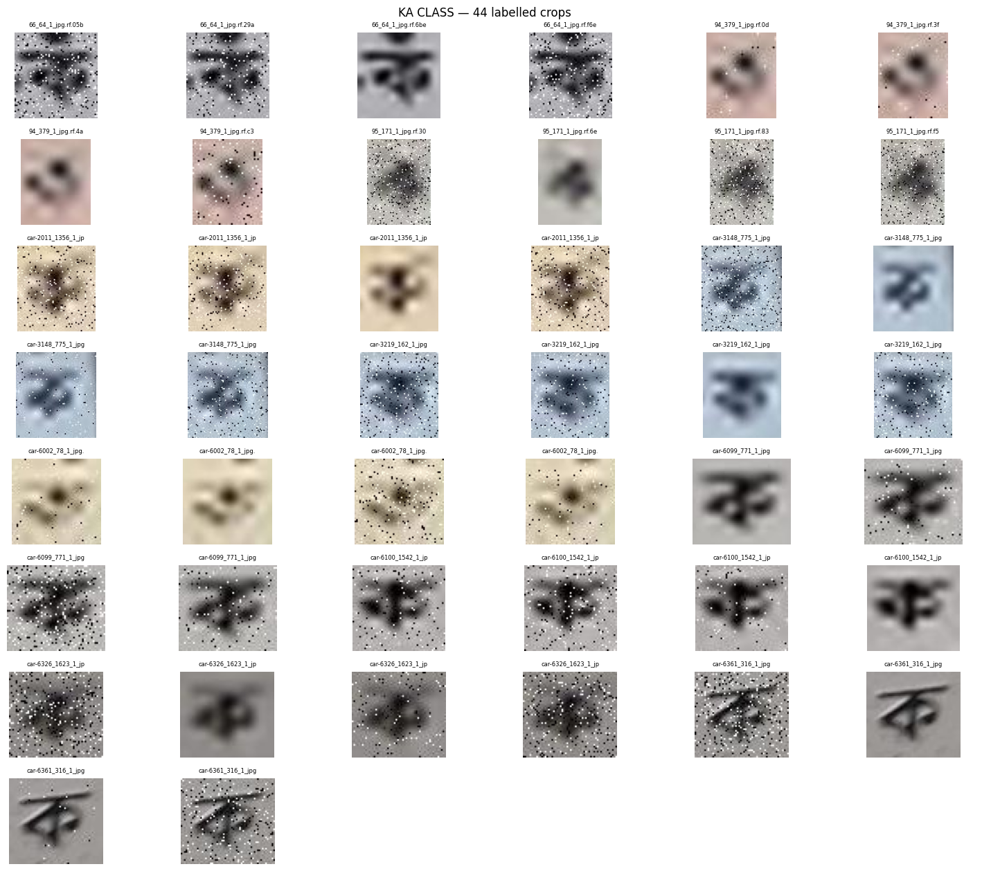

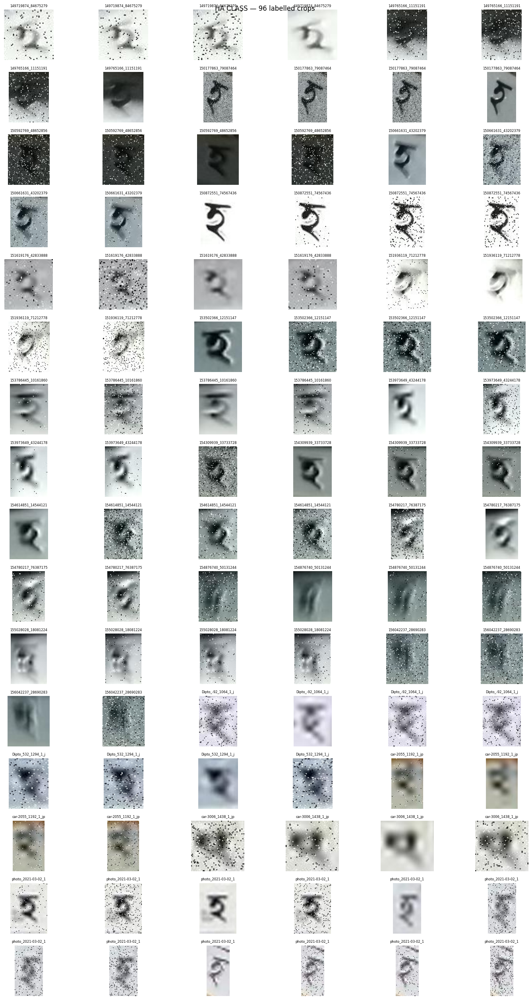

In [18]:

from pathlib import Path
import math
import cv2
import matplotlib.pyplot as plt

DATA_ROOT = Path("/content/bd_plate_character_dataset")
IMAGE_DIR = DATA_ROOT / "images" / "train"
LABEL_DIR = DATA_ROOT / "labels" / "train"

def collect_character_crops(target_class):
    crops = []

    for label_file in sorted(LABEL_DIR.glob("*.txt")):
        image_path = next(
            (
                p for p in IMAGE_DIR.glob(label_file.stem + ".*")
                if p.suffix.lower() in {
                    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".jfif"
                }
            ),
            None
        )

        if image_path is None:
            continue

        image = cv2.imread(str(image_path))
        if image is None:
            continue

        height, width = image.shape[:2]

        for line in label_file.read_text(
            encoding="utf-8"
        ).splitlines():
            parts = line.split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            if class_id != target_class:
                continue

            xc, yc, bw, bh = map(float, parts[1:])

            x1 = max(0, int((xc - bw / 2) * width))
            y1 = max(0, int((yc - bh / 2) * height))
            x2 = min(width, int((xc + bw / 2) * width))
            y2 = min(height, int((yc + bh / 2) * height))

            if x2 <= x1 or y2 <= y1:
                continue

            crop = image[y1:y2, x1:x2]

            if crop.size:
                crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
                crops.append((label_file.stem, crop))

    return crops

def show_contact_sheet(crops, title):
    if not crops:
        print(f"No crops found for {title}")
        return

    columns = 6
    rows = math.ceil(len(crops) / columns)

    fig, axes = plt.subplots(
        rows, columns,
        figsize=(15, max(3, rows * 1.6))
    )
    axes = axes.flatten()

    for ax, (filename, crop) in zip(axes, crops):
        ax.imshow(crop)
        ax.set_title(filename[:18], fontsize=6)
        ax.axis("off")

    for ax in axes[len(crops):]:
        ax.axis("off")

    fig.suptitle(f"{title} — {len(crops)} labelled crops")
    plt.tight_layout()
    plt.show()

ka_crops = collect_character_crops(20)
ha_crops = collect_character_crops(17)

print("KA (ক) crops:", len(ka_crops))
print("HA (হ) crops:", len(ha_crops))

show_contact_sheet(ka_crops, "KA CLASS")
show_contact_sheet(ha_crops, "HA CLASS")


In [19]:

from pathlib import Path
from datetime import datetime
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

BASE_MODEL = PROJECT / "models" / "character" / "character_best.pt"

DATA_YAML = Path(
    "/content/bd_plate_character_ka_aug_20261018_144741/data.yaml"
)

RUNS_DIR = PROJECT / "experiments"
RUN_NAME = f"ka_controlled_{datetime.now():%Y%m%d_%H%M%S}"

if not torch.cuda.is_available():
    raise RuntimeError("Enable a GPU runtime before training.")

if not BASE_MODEL.exists():
    raise FileNotFoundError(f"Base model not found: {BASE_MODEL}")

if not DATA_YAML.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_YAML}")

RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("Starting from original model:", BASE_MODEL)
print("Dataset:", DATA_YAML)
print("Experiment:", RUN_NAME)

model = YOLO(str(BASE_MODEL))

model.train(
    data=str(DATA_YAML),
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=8,
    optimizer="AdamW",
    lr0=0.0002,
    lrf=0.01,
    seed=42,
    deterministic=True,
    fliplr=0.0,
    flipud=0.0,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    degrees=0.0,
    translate=0.02,
    scale=0.1,
    shear=0.0,
    perspective=0.0,
    hsv_h=0.0,
    hsv_s=0.1,
    hsv_v=0.1,
    erasing=0.0,
    close_mosaic=0,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,
    save=True,
    save_period=5,
    plots=True,
    cache=False,
    verbose=True
)

BEST_MODEL = RUNS_DIR / RUN_NAME / "weights" / "best.pt"

if not BEST_MODEL.exists():
    raise FileNotFoundError(f"Best model not found: {BEST_MODEL}")

print("\nTraining completed.")
print("Experimental model:", BEST_MODEL)
print("Original model remains unchanged.")


GPU: Tesla T4
Starting from original model: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/models/character/character_best.pt
Dataset: /content/bd_plate_character_ka_aug_20261018_144741/data.yaml
Experiment: ka_controlled_20261018_154712
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bd_plate_character_ka_aug_20261018_144741/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None

In [20]:

from pathlib import Path
import cv2
import numpy as np
import torch
from google.colab import files
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

LOCALIZER = PROJECT / "models/localization/localization_best.pt"
ORIGINAL = PROJECT / "models/character/character_best.pt"
CONTROLLED = (
    PROJECT / "experiments/ka_controlled_20261018_154712"
    / "weights/best.pt"
)

for path in [LOCALIZER, ORIGINAL, CONTROLLED]:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

image_path = Path("/content/unseen_vehicle_01.jpg")

if not image_path.exists():
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No image uploaded.")
    filename = next(iter(uploaded))
    image_path = Path("/content") / filename
    image_path.write_bytes(uploaded[filename])

image = cv2.imread(str(image_path))
if image is None:
    raise ValueError("Could not read the image.")

device = 0 if torch.cuda.is_available() else "cpu"

localizer = YOLO(str(LOCALIZER))
original = YOLO(str(ORIGINAL))
controlled = YOLO(str(CONTROLLED))

result = localizer.predict(
    image, conf=0.25, imgsz=640,
    device=device, verbose=False
)[0]

if result.boxes is None or len(result.boxes) == 0:
    raise RuntimeError("No plate detected.")

index = int(result.boxes.conf.argmax())
x1, y1, x2, y2 = map(
    int, result.boxes.xyxy[index].cpu().numpy()
)

h, w = image.shape[:2]
bw, bh = x2 - x1, y2 - y1

crop = image[
    max(0, y1 - int(bh * 0.15)):
    min(h, y2 + int(bh * 0.15)),
    max(0, x1 - int(bw * 0.05)):
    min(w, x2 + int(bw * 0.35))
]

print("Plate crop:", crop.shape)

for name, model in [
    ("ORIGINAL", original),
    ("CONTROLLED", controlled)
]:
    pred = model.predict(
        crop, conf=0.15, imgsz=640,
        device=device, verbose=False
    )[0]

    print(f"\n===== {name} MODEL =====")

    if pred.boxes is None:
        print("No detections")
        continue

    detections = []
    for box, conf, cls in zip(
        pred.boxes.xyxy.cpu().numpy(),
        pred.boxes.conf.cpu().numpy(),
        pred.boxes.cls.cpu().numpy()
    ):
        cx = float((box[0] + box[2]) / 2)
        cy = float((box[1] + box[3]) / 2)
        detections.append(
            (cy, cx, pred.names[int(cls)], float(conf))
        )

    for cy, cx, label, conf in sorted(detections):
        print(
            f"class={label}, confidence={conf:.3f}, "
            f"x={cx:.1f}, y={cy:.1f}"
        )


Plate crop: (202, 422, 3)

===== ORIGINAL MODEL =====
class=chattogram, confidence=0.996, x=85.1, y=70.5
class=metro, confidence=0.882, x=169.9, y=70.9
class=ka, confidence=0.209, x=249.3, y=71.0
class=ha, confidence=0.523, x=249.2, y=71.1
class=1, confidence=0.857, x=57.1, y=121.1
class=0, confidence=0.896, x=155.5, y=121.3
class=1, confidence=0.876, x=94.5, y=121.4
class=3, confidence=0.852, x=229.4, y=122.1
class=1, confidence=0.877, x=265.7, y=122.5
class=8, confidence=0.888, x=191.8, y=122.7

===== CONTROLLED MODEL =====
class=chattogram, confidence=0.847, x=84.7, y=69.4
class=metro, confidence=0.881, x=169.7, y=70.9
class=1, confidence=0.874, x=57.0, y=121.3
class=0, confidence=0.899, x=155.0, y=121.5
class=1, confidence=0.875, x=95.0, y=122.1
class=8, confidence=0.900, x=191.8, y=122.6
class=3, confidence=0.922, x=229.7, y=122.8
class=1, confidence=0.885, x=266.3, y=123.9



===== ORIGINAL MODEL: RAW BOXES =====
{'label': 'chattogram', 'confidence': 0.996, 'xyxy': [54, 45, 115, 95]}
{'label': '0', 'confidence': 0.8961, 'xyxy': [136, 94, 174, 148]}
{'label': '8', 'confidence': 0.8885, 'xyxy': [173, 95, 210, 149]}
{'label': 'metro', 'confidence': 0.8822, 'xyxy': [119, 46, 220, 94]}
{'label': '1', 'confidence': 0.8766, 'xyxy': [246, 95, 284, 149]}
{'label': '1', 'confidence': 0.8758, 'xyxy': [75, 94, 113, 148]}
{'label': '1', 'confidence': 0.8573, 'xyxy': [37, 94, 76, 148]}
{'label': '3', 'confidence': 0.8524, 'xyxy': [210, 96, 248, 148]}
{'label': 'ha', 'confidence': 0.5235, 'xyxy': [228, 50, 269, 91]}
{'label': 'ka', 'confidence': 0.2092, 'xyxy': [228, 51, 270, 90]}
{'label': 'jashore', 'confidence': 0.0315, 'xyxy': [54, 47, 114, 95]}
{'label': '0', 'confidence': 0.0238, 'xyxy': [112, 94, 137, 139]}


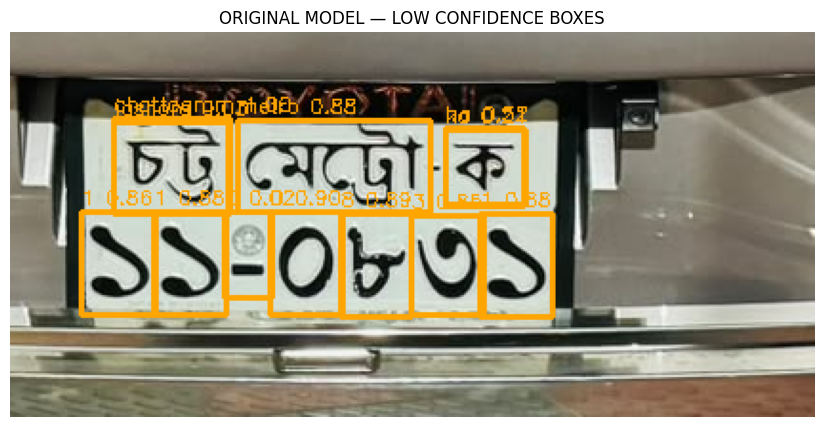


===== CONTROLLED MODEL: RAW BOXES =====
{'label': '3', 'confidence': 0.9223, 'xyxy': [210, 95, 249, 150]}
{'label': '8', 'confidence': 0.9003, 'xyxy': [173, 94, 209, 150]}
{'label': '0', 'confidence': 0.8992, 'xyxy': [135, 93, 174, 149]}
{'label': '1', 'confidence': 0.8854, 'xyxy': [246, 95, 285, 152]}
{'label': 'metro', 'confidence': 0.8806, 'xyxy': [119, 46, 220, 95]}
{'label': '1', 'confidence': 0.8745, 'xyxy': [74, 94, 115, 150]}
{'label': '1', 'confidence': 0.874, 'xyxy': [36, 92, 77, 150]}
{'label': 'chattogram', 'confidence': 0.8474, 'xyxy': [54, 44, 115, 94]}
{'label': 'ka', 'confidence': 0.1114, 'xyxy': [229, 52, 270, 90]}
{'label': 'ha', 'confidence': 0.041, 'xyxy': [229, 51, 270, 91]}
{'label': 'da', 'confidence': 0.0203, 'xyxy': [54, 43, 114, 96]}


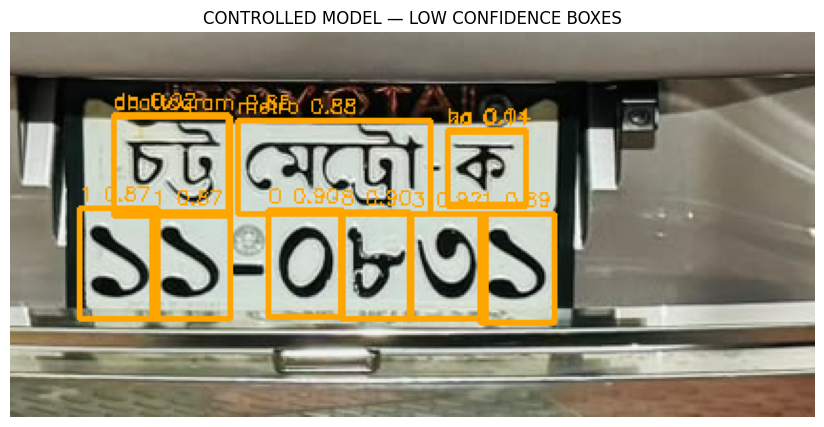

In [21]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

LOCALIZER_PATH = PROJECT / "models/localization/localization_best.pt"
ORIGINAL_PATH = PROJECT / "models/character/character_best.pt"
CONTROLLED_PATH = (
    PROJECT / "experiments/ka_controlled_20261018_154712"
    / "weights/best.pt"
)

IMAGE_PATH = Path("/content/unseen_vehicle_01.jpg")

for path in [
    LOCALIZER_PATH,
    ORIGINAL_PATH,
    CONTROLLED_PATH,
    IMAGE_PATH
]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

device = 0 if torch.cuda.is_available() else "cpu"

image = cv2.imread(str(IMAGE_PATH))
localizer = YOLO(str(LOCALIZER_PATH))
original = YOLO(str(ORIGINAL_PATH))
controlled = YOLO(str(CONTROLLED_PATH))

plate_result = localizer.predict(
    image,
    conf=0.25,
    imgsz=640,
    device=device,
    verbose=False
)[0]

if plate_result.boxes is None or len(plate_result.boxes) == 0:
    raise RuntimeError("No plate detected.")

best_index = int(plate_result.boxes.conf.argmax())
x1, y1, x2, y2 = map(
    int, plate_result.boxes.xyxy[best_index].cpu().numpy()
)

h, w = image.shape[:2]
bw, bh = x2 - x1, y2 - y1

crop = image[
    max(0, y1 - int(bh * 0.15)):
    min(h, y2 + int(bh * 0.15)),
    max(0, x1 - int(bw * 0.05)):
    min(w, x2 + int(bw * 0.35))
]

for name, model in [
    ("ORIGINAL", original),
    ("CONTROLLED", controlled)
]:
    result = model.predict(
        crop,
        conf=0.01,
        iou=0.7,
        imgsz=640,
        device=device,
        verbose=False
    )[0]

    print(f"\n===== {name} MODEL: RAW BOXES =====")

    canvas = crop.copy()

    if result.boxes is not None:
        boxes = result.boxes.xyxy.cpu().numpy()
        confidences = result.boxes.conf.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy()

        for box, confidence, class_id in zip(
            boxes, confidences, classes
        ):
            bx1, by1, bx2, by2 = map(int, box)
            label = result.names[int(class_id)]

            print({
                "label": label,
                "confidence": round(float(confidence), 4),
                "xyxy": [bx1, by1, bx2, by2]
            })

            cv2.rectangle(
                canvas,
                (bx1, by1),
                (bx2, by2),
                (0, 165, 255),
                2
            )

            cv2.putText(
                canvas,
                f"{label} {confidence:.2f}",
                (bx1, max(12, by1 - 4)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.35,
                (0, 165, 255),
                1
            )

    plt.figure(figsize=(12, 5))
    plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    plt.title(f"{name} MODEL — LOW CONFIDENCE BOXES")
    plt.axis("off")
    plt.show()


KA — ক: 44 source groups


/tmp/ipykernel_530/454726785.py:97: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_530/454726785.py:97: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Bengali natively.
  fig.canvas.print_figure(bytes_io, **kw)


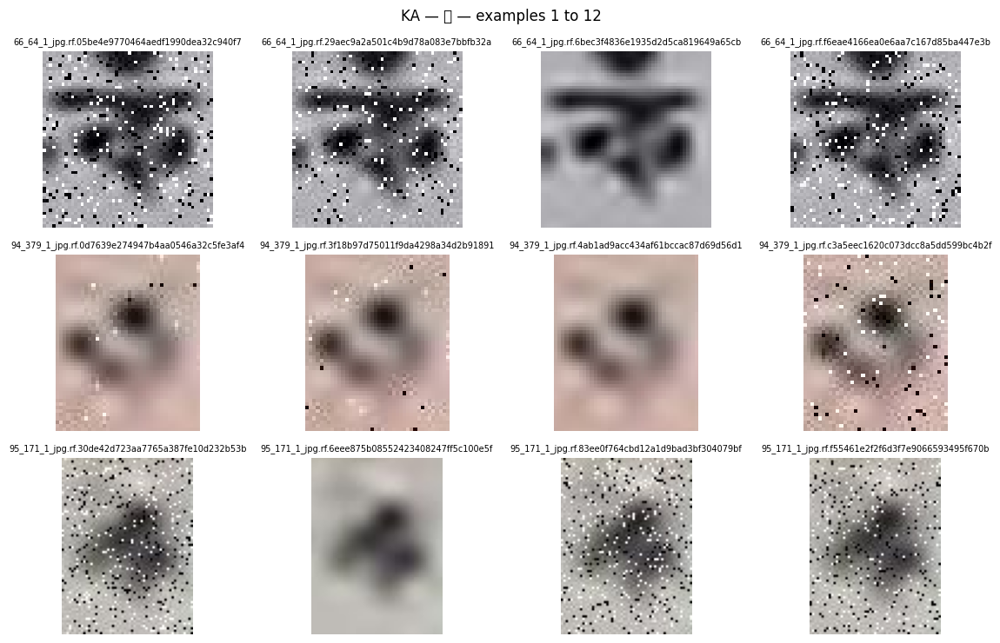

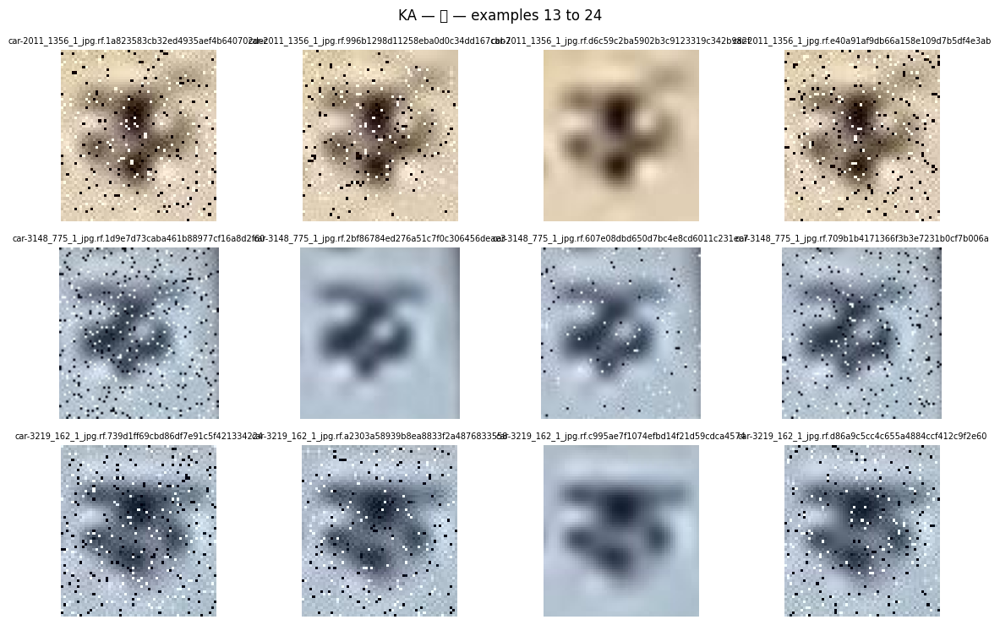

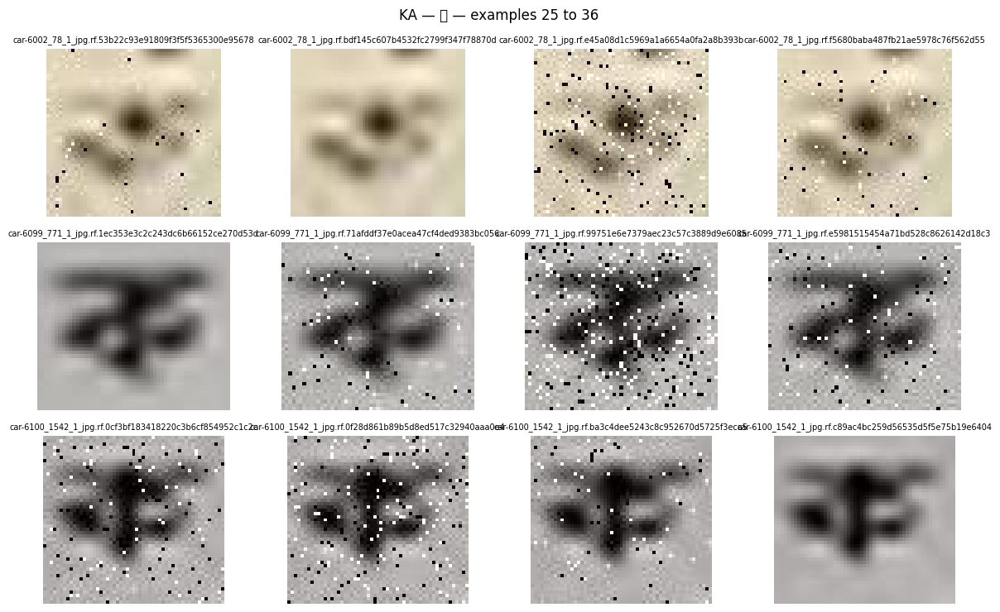

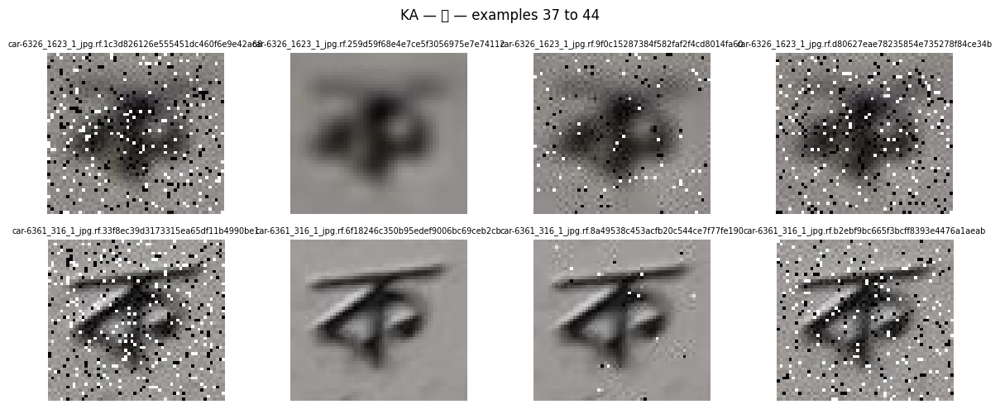

HA — হ: 96 source groups


/tmp/ipykernel_530/454726785.py:97: UserWarning: Glyph 2489 (\N{BENGALI LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2489 (\N{BENGALI LETTER HA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


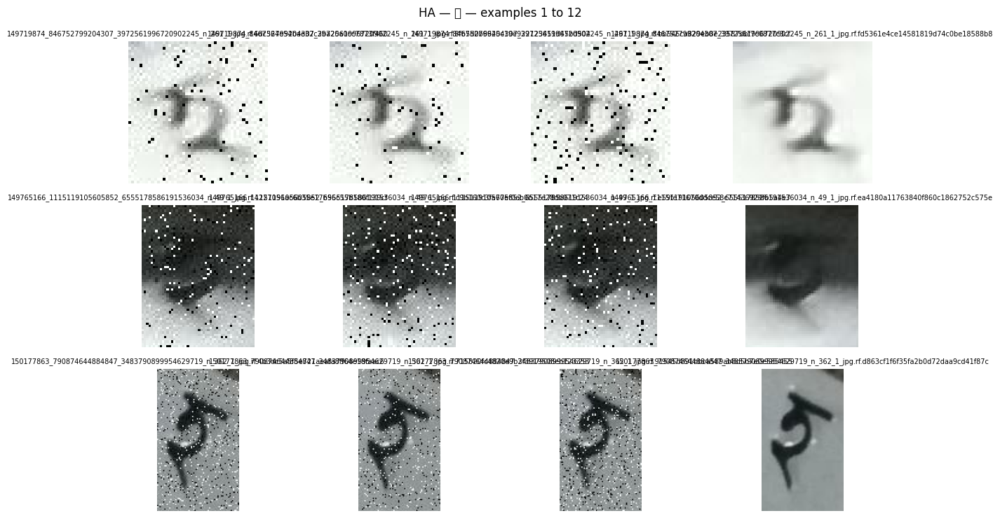

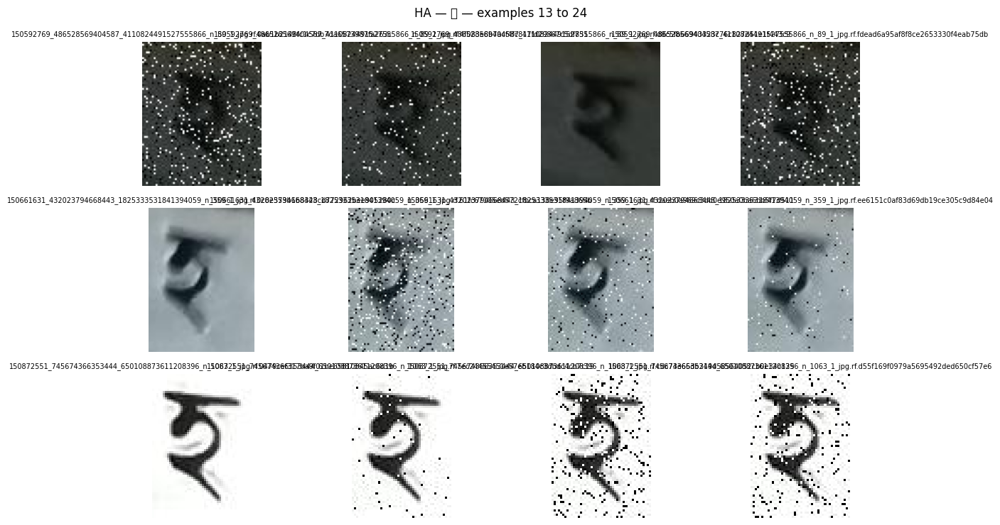

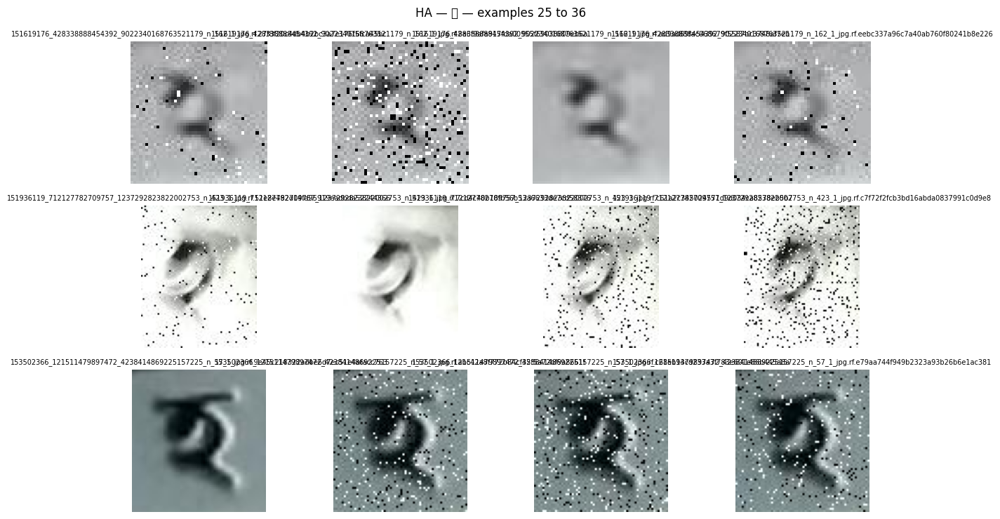

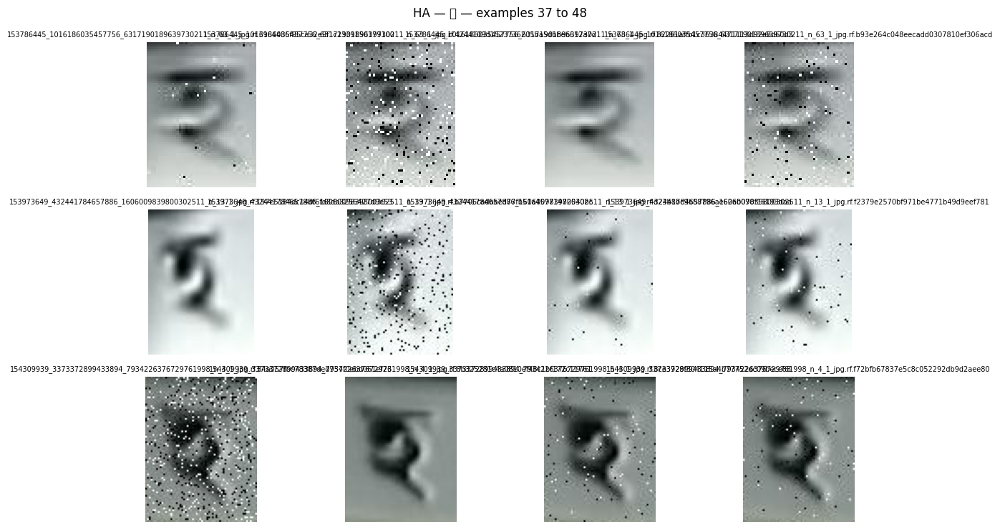

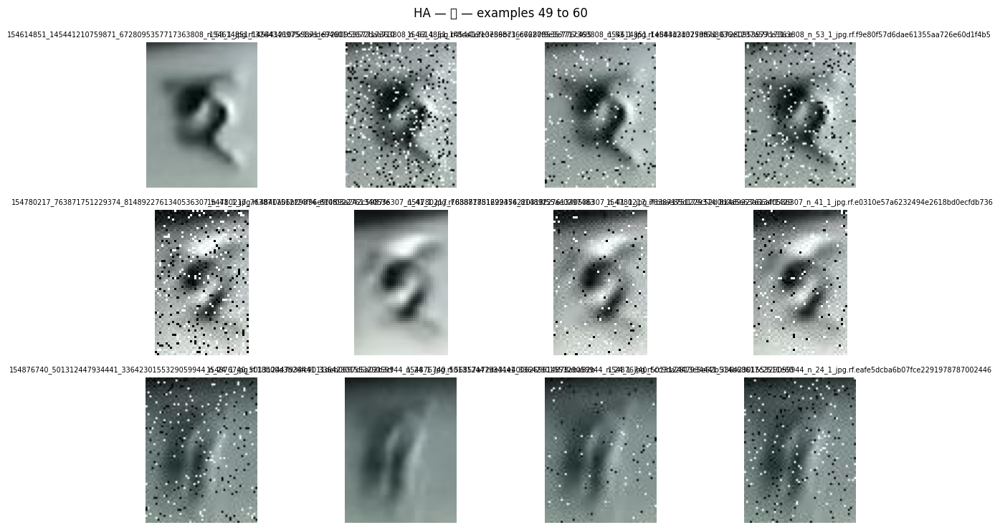

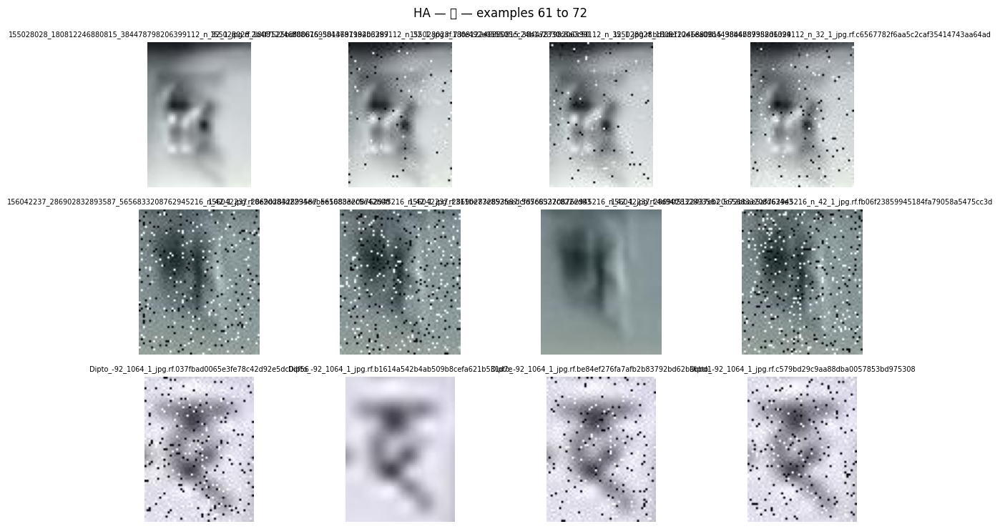

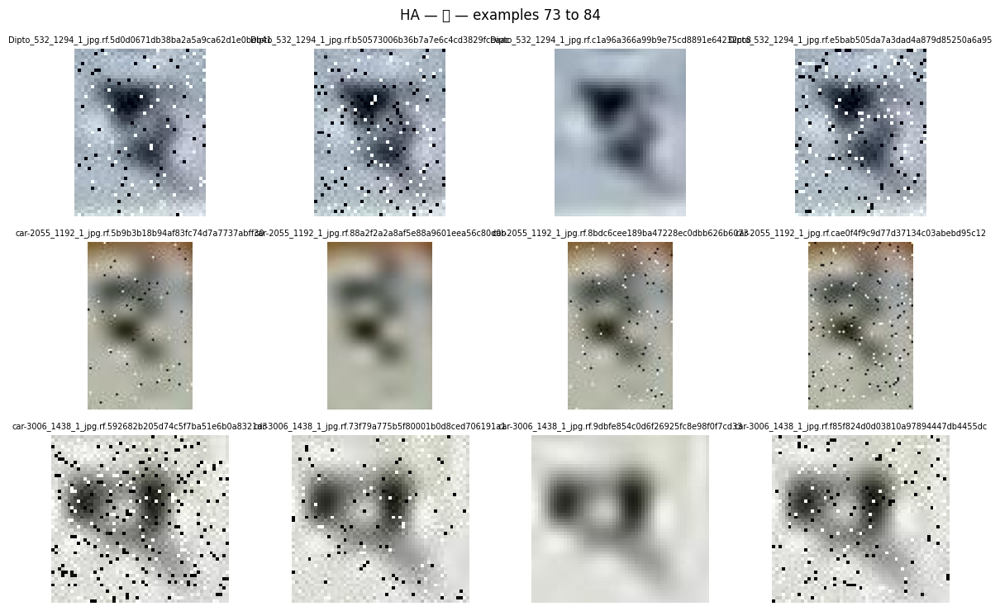

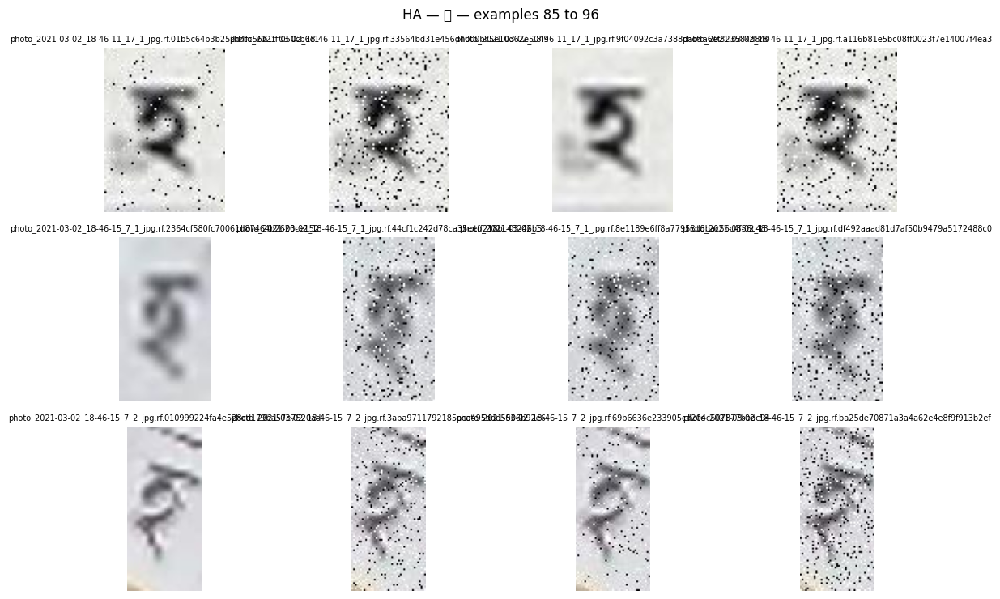

In [22]:

from pathlib import Path
import re
import math
import cv2
import matplotlib.pyplot as plt

ROOT = Path("/content/bd_plate_character_dataset")
IMAGE_DIR = ROOT / "images" / "train"
LABEL_DIR = ROOT / "labels" / "train"

def source_key(stem):
    match = re.search(
        r"(?i)(\.jpe?g|\.png|\.webp|\.jfif)\.",
        stem
    )
    if match:
        return stem[:match.end() - 1]
    return stem

def collect_unique_crops(class_id):
    unique = {}

    for label_file in sorted(LABEL_DIR.glob("*.txt")):
        image_path = next(
            (
                p for p in IMAGE_DIR.glob(label_file.stem + ".*")
                if p.suffix.lower() in {
                    ".jpg", ".jpeg", ".png",
                    ".bmp", ".webp", ".jfif"
                }
            ),
            None
        )

        if image_path is None:
            continue

        image = cv2.imread(str(image_path))
        if image is None:
            continue

        h, w = image.shape[:2]

        for line in label_file.read_text(
            encoding="utf-8"
        ).splitlines():
            parts = line.split()

            if len(parts) != 5 or int(parts[0]) != class_id:
                continue

            xc, yc, bw, bh = map(float, parts[1:])
            x1 = max(0, int((xc - bw / 2) * w))
            y1 = max(0, int((yc - bh / 2) * h))
            x2 = min(w, int((xc + bw / 2) * w))
            y2 = min(h, int((yc + bh / 2) * h))

            if x2 <= x1 or y2 <= y1:
                continue

            key = source_key(label_file.stem)

            if key not in unique:
                crop = image[y1:y2, x1:x2]
                unique[key] = (
                    key,
                    cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
                )

    return list(unique.values())

def show_pages(items, title, per_page=12):
    print(f"{title}: {len(items)} source groups")

    for start in range(0, len(items), per_page):
        batch = items[start:start + per_page]
        columns = 4
        rows = math.ceil(len(batch) / columns)

        fig, axes = plt.subplots(
            rows, columns,
            figsize=(12, rows * 2.5),
            squeeze=False
        )

        for ax in axes.flat:
            ax.axis("off")

        for ax, (name, crop) in zip(axes.flat, batch):
            ax.imshow(crop)
            ax.set_title(name, fontsize=7)
            ax.axis("off")

        fig.suptitle(
            f"{title} — examples {start + 1} to {start + len(batch)}"
        )
        plt.tight_layout()
        plt.show()

ka_items = collect_unique_crops(20)
ha_items = collect_unique_crops(17)

show_pages(ka_items, "KA — ক")
show_pages(ha_items, "HA — হ")


Unique HA source images: 24
Showing examples 1–12


/tmp/ipykernel_530/379536188.py:98: UserWarning: Glyph 2489 (\N{BENGALI LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_530/379536188.py:98: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()


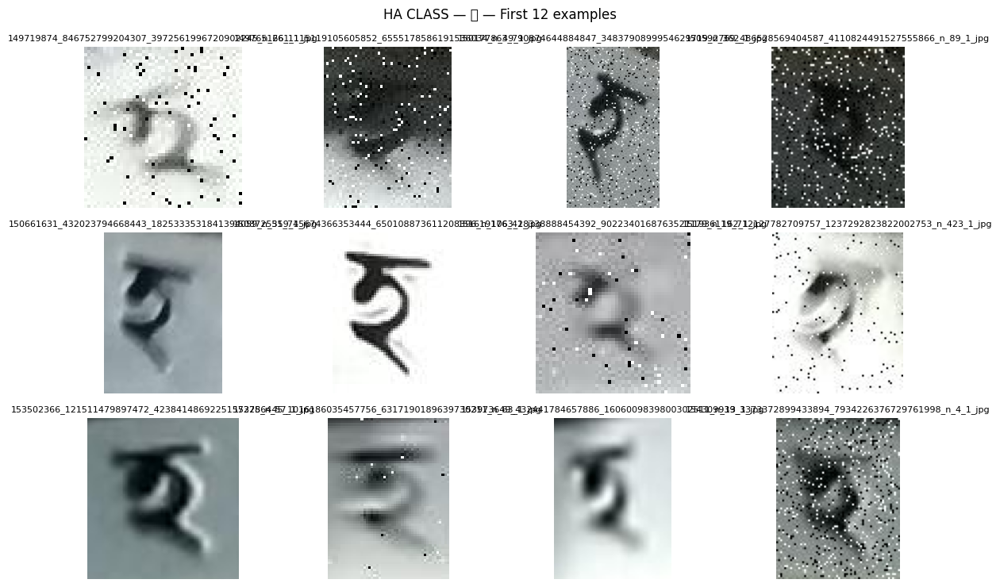

In [23]:

from pathlib import Path
import re
import math
import cv2
import matplotlib.pyplot as plt

ROOT = Path("/content/bd_plate_character_dataset")
IMAGE_DIR = ROOT / "images" / "train"
LABEL_DIR = ROOT / "labels" / "train"

ha_crops = {}

for label_file in sorted(LABEL_DIR.glob("*.txt")):
    lines = label_file.read_text(encoding="utf-8").splitlines()

    ha_lines = [
        line.split()
        for line in lines
        if line.strip() and line.split()[0] == "17"
    ]

    if not ha_lines:
        continue

    image_path = next(
        (
            p for p in IMAGE_DIR.glob(label_file.stem + ".*")
            if p.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".jfif"
            }
        ),
        None
    )

    if image_path is None:
        continue

    source_key = re.sub(
        r"\.rf\..*$", "", label_file.stem
    )
    source_key = re.sub(
        r"__ka_aug.*$", "", source_key
    )

    if source_key in ha_crops:
        continue

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    height, width = image.shape[:2]
    _, xc, yc, bw, bh = ha_lines[0]
    xc, yc, bw, bh = map(float, [xc, yc, bw, bh])

    x1 = max(0, int((xc - bw / 2) * width))
    y1 = max(0, int((yc - bh / 2) * height))
    x2 = min(width, int((xc + bw / 2) * width))
    y2 = min(height, int((yc + bh / 2) * height))

    if x2 <= x1 or y2 <= y1:
        continue

    crop = image[y1:y2, x1:x2]
    ha_crops[source_key] = cv2.cvtColor(
        crop, cv2.COLOR_BGR2RGB
    )

items = list(sorted(ha_crops.items()))

print("Unique HA source images:", len(items))
print("Showing examples 1–12")

batch = items[:12]

if not batch:
    print("No HA crops found. Check the dataset paths.")
else:
    columns = 4
    rows = math.ceil(len(batch) / columns)

    fig, axes = plt.subplots(
        rows, columns,
        figsize=(12, rows * 2.5),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (name, crop) in zip(axes.flat, batch):
        ax.imshow(crop)
        ax.set_title(name, fontsize=8)
        ax.axis("off")

    fig.suptitle("HA CLASS — হ — First 12 examples")
    plt.tight_layout()
    plt.show()


In [24]:

from pathlib import Path

ROOT = Path("/content/bd_plate_character_dataset")
SPLITS = ["train", "validation", "test"]

KA_ID = 20
HA_ID = 17
IOU_THRESHOLD = 0.5

def iou_xywh(a, b):
    ax1 = a[0] - a[2] / 2
    ay1 = a[1] - a[3] / 2
    ax2 = a[0] + a[2] / 2
    ay2 = a[1] + a[3] / 2

    bx1 = b[0] - b[2] / 2
    by1 = b[1] - b[3] / 2
    bx2 = b[0] + b[2] / 2
    by2 = b[1] + b[3] / 2

    iw = max(0, min(ax2, bx2) - max(ax1, bx1))
    ih = max(0, min(ay2, by2) - max(ay1, by1))
    intersection = iw * ih

    union = a[2] * a[3] + b[2] * b[3] - intersection

    return intersection / union if union > 0 else 0.0

for split in SPLITS:
    label_dir = ROOT / "labels" / split
    conflicts = []

    for label_file in sorted(label_dir.glob("*.txt")):
        ka_boxes = []
        ha_boxes = []

        for line in label_file.read_text(
            encoding="utf-8"
        ).splitlines():
            parts = line.split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])
            box = tuple(map(float, parts[1:]))

            if class_id == KA_ID:
                ka_boxes.append(box)
            elif class_id == HA_ID:
                ha_boxes.append(box)

        for ka_box in ka_boxes:
            for ha_box in ha_boxes:
                overlap = iou_xywh(ka_box, ha_box)

                if overlap >= IOU_THRESHOLD:
                    conflicts.append({
                        "file": label_file.name,
                        "IoU": round(overlap, 3),
                        "ka_box": ka_box,
                        "ha_box": ha_box
                    })

    print(f"\n===== {split.upper()} =====")
    print("Overlapping ka/ha annotation pairs:", len(conflicts))

    for item in conflicts[:20]:
        print(item)

    if not conflicts:
        print("No overlapping ka/ha annotations found.")



===== TRAIN =====
Overlapping ka/ha annotation pairs: 0
No overlapping ka/ha annotations found.

===== VALIDATION =====
Overlapping ka/ha annotation pairs: 0
No overlapping ka/ha annotations found.

===== TEST =====
Overlapping ka/ha annotation pairs: 0
No overlapping ka/ha annotations found.


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,603,369 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 524.8±186.4 MB/s, size: 9.4 KB)
val: Scanning /content/bd_plate_character_ka_aug_20261018_144741/labels/validation.cache... 363 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 363/363 108.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 3.3it/s 7.0s
                   all        363       3180      0.913      0.921      0.939      0.708
                     0        178        248      0.988      0.978      0.993      0.732
                     1        275        499      0.988      0.988      0.994      0.741
                     2        181        245          1      0.988      0.995      0.733
                     3        179        241      0.988       0.99      0.995      0.739
       

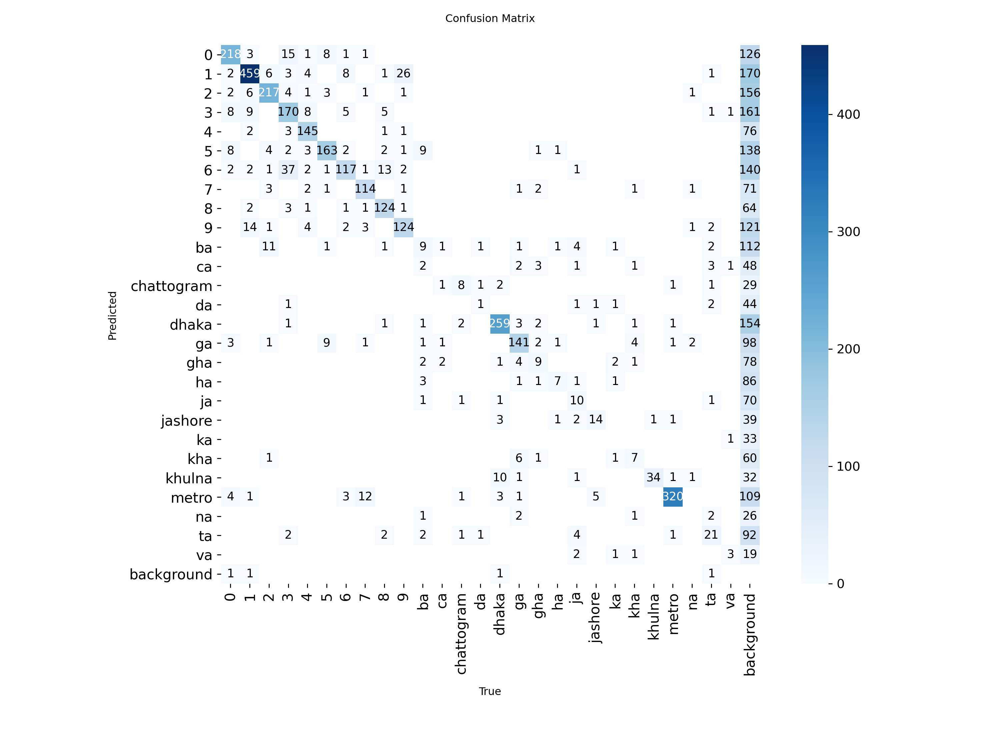


confusion_matrix_normalized.png


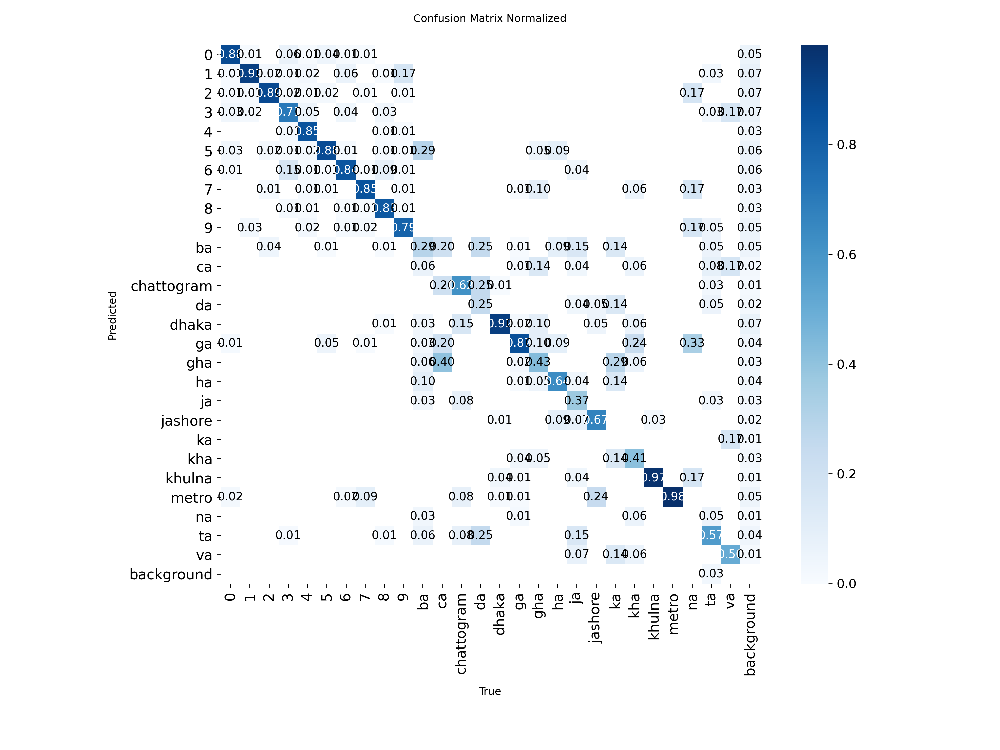


Validation complete. Original model unchanged.


In [27]:

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display, Image

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

MODEL_PATH = PROJECT / "models" / "character" / "character_best.pt"

DATA_YAML = Path(
    "/content/bd_plate_character_ka_aug_20261018_144741/data.yaml"
)

OUTPUT_DIR = Path("/content/bd_platevision_ka_ha_audit")

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not DATA_YAML.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_YAML}")

model = YOLO(str(MODEL_PATH))

results = model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    plots=True,
    project=str(OUTPUT_DIR),
    name="original_confusion_matrix",
    exist_ok=True,
    verbose=True
)

run_dir = OUTPUT_DIR / "original_confusion_matrix"

for filename in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]:
    plot_path = run_dir / filename

    if plot_path.exists():
        print(f"\n{filename}")
        display(Image(filename=str(plot_path), width=900))
    else:
        print("Plot not found:", plot_path)

print("\nValidation complete. Original model unchanged.")


Ground-truth KA instances checked: 7
Potential KA detection errors: 4
{'image': 'car-6081_222_1_jpg.rf.388dbf97cae9da83a186ab0fb6d4a381.jpg', 'prediction': 'ba', 'confidence': 0.126, 'IoU': 0.907}
{'image': 'car-6124_1_1_jpg.rf.d6761fb2193d00226cd4f3346dcbc307.jpg', 'prediction': 'ba', 'confidence': 0.051, 'IoU': 0.894}
{'image': 'car-6254_1860_1_jpg.rf.479fbd08d88298265be3f28dc9755b64.jpg', 'prediction': 'gha', 'confidence': 0.698, 'IoU': 0.805}
{'image': 'car-6362_701_1_jpg.rf.4728f96c197b3e976236692e62d7fc0a.jpg', 'prediction': 'ba', 'confidence': 0.23, 'IoU': 0.869}


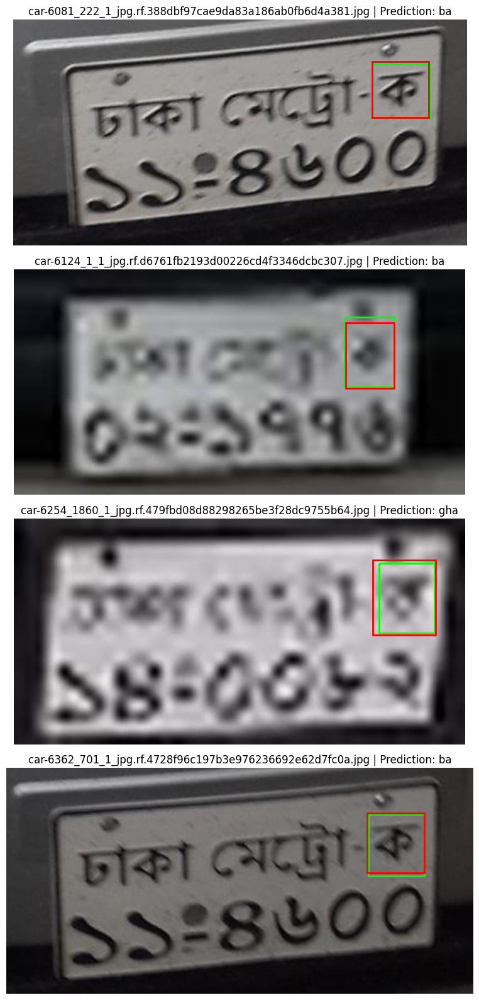

In [28]:

from pathlib import Path
import cv2
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)
MODEL_PATH = PROJECT / "models/character/character_best.pt"
DATA_ROOT = Path("/content/bd_plate_character_dataset")
IMAGE_DIR = DATA_ROOT / "images" / "validation"
LABEL_DIR = DATA_ROOT / "labels" / "validation"

model = YOLO(str(MODEL_PATH))
device = 0 if torch.cuda.is_available() else "cpu"

def iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])

    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".jfif"}
image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
)

errors = []
checked = 0

for image_path in image_paths:
    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    if not label_path.exists():
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        continue

    height, width = image.shape[:2]
    gt_ka_boxes = []

    for line in label_path.read_text(encoding="utf-8").splitlines():
        parts = line.split()
        if len(parts) != 5 or int(parts[0]) != 20:
            continue

        _, xc, yc, bw, bh = parts
        xc, yc, bw, bh = map(float, [xc, yc, bw, bh])

        gt_ka_boxes.append([
            (xc - bw / 2) * width,
            (yc - bh / 2) * height,
            (xc + bw / 2) * width,
            (yc + bh / 2) * height
        ])

    if not gt_ka_boxes:
        continue

    result = model.predict(
        source=image,
        conf=0.01,
        imgsz=640,
        device=device,
        verbose=False
    )[0]

    predictions = []

    if result.boxes is not None:
        for box, conf, cls in zip(
            result.boxes.xyxy.cpu().numpy(),
            result.boxes.conf.cpu().numpy(),
            result.boxes.cls.cpu().numpy()
        ):
            predictions.append({
                "box": box.tolist(),
                "label": result.names[int(cls)],
                "class_id": int(cls),
                "confidence": float(conf)
            })

    for gt_box in gt_ka_boxes:
        checked += 1

        matched = [
            (iou_xyxy(gt_box, pred["box"]), pred)
            for pred in predictions
            if iou_xyxy(gt_box, pred["box"]) >= 0.3
        ]

        if not matched:
            errors.append({
                "image": image_path,
                "gt": gt_box,
                "pred": None,
                "iou": 0.0
            })
            continue

        best_iou, best_pred = max(matched, key=lambda item: item[0])

        if best_pred["class_id"] != 20:
            errors.append({
                "image": image_path,
                "gt": gt_box,
                "pred": best_pred,
                "iou": best_iou
            })

print("Ground-truth KA instances checked:", checked)
print("Potential KA detection errors:", len(errors))

for item in errors:
    pred = item["pred"]
    print({
        "image": item["image"].name,
        "prediction": pred["label"] if pred else "missed",
        "confidence": round(pred["confidence"], 3) if pred else None,
        "IoU": round(item["iou"], 3)
    })

if errors:
    shown = errors[:6]
    fig, axes = plt.subplots(
        len(shown), 1,
        figsize=(12, 4 * len(shown)),
        squeeze=False
    )

    for ax, item in zip(axes.flat, shown):
        image = cv2.cvtColor(
            cv2.imread(str(item["image"])),
            cv2.COLOR_BGR2RGB
        )

        gx1, gy1, gx2, gy2 = map(int, item["gt"])
        ax.imshow(image)
        ax.add_patch(
            plt.Rectangle(
                (gx1, gy1), gx2 - gx1, gy2 - gy1,
                fill=False, edgecolor="lime", linewidth=2
            )
        )

        pred = item["pred"]
        if pred:
            px1, py1, px2, py2 = map(int, pred["box"])
            ax.add_patch(
                plt.Rectangle(
                    (px1, py1), px2 - px1, py2 - py1,
                    fill=False, edgecolor="red", linewidth=2
                )
            )

        ax.set_title(
            f'{item["image"].name} | '
            f'Prediction: {pred["label"] if pred else "missed"}'
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No KA misclassifications found at IoU >= 0.3.")



===== car-6081_222_1_jpg.rf.388dbf97cae9da83a186ab0fb6d4a381.jpg =====
{'class': 'ka', 'confidence': 0.9237, 'IoU': 0.901, 'box': [329.1, 37.6, 382.5, 89.5]}
{'class': 'ba', 'confidence': 0.1263, 'IoU': 0.907, 'box': [329.1, 38.3, 381.6, 90.0]}
{'class': 'ba', 'confidence': 0.0316, 'IoU': 0.894, 'box': [329.2, 37.5, 382.5, 89.0]}
{'class': 'ba', 'confidence': 0.0097, 'IoU': 0.89, 'box': [329.1, 39.3, 380.4, 89.2]}


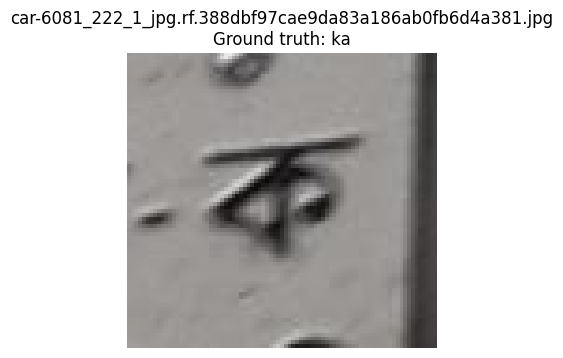


===== car-6124_1_1_jpg.rf.d6761fb2193d00226cd4f3346dcbc307.jpg =====
{'class': 'ka', 'confidence': 0.5827, 'IoU': 0.857, 'box': [305.7, 49.0, 352.5, 108.9]}
{'class': 'ba', 'confidence': 0.0513, 'IoU': 0.894, 'box': [305.1, 49.5, 350.1, 109.8]}
{'class': 'ba', 'confidence': 0.0048, 'IoU': 0.857, 'box': [305.1, 48.9, 352.1, 107.5]}
{'class': 'ba', 'confidence': 0.0015, 'IoU': 0.883, 'box': [305.1, 48.8, 350.1, 106.8]}


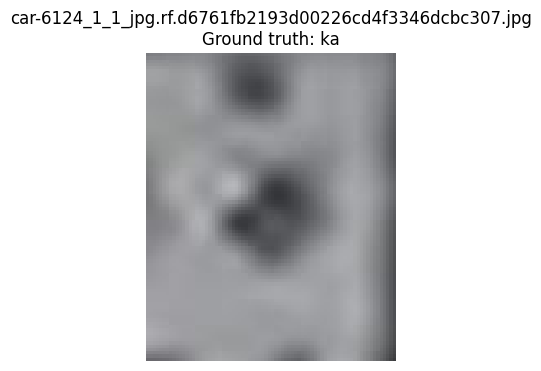


===== car-6254_1860_1_jpg.rf.479fbd08d88298265be3f28dc9755b64.jpg =====
{'class': 'gha', 'confidence': 0.6979, 'IoU': 0.805, 'box': [330.6, 38.4, 388.9, 107.9]}
{'class': 'gha', 'confidence': 0.6231, 'IoU': 0.791, 'box': [330.7, 37.9, 390.8, 106.6]}
{'class': 'gha', 'confidence': 0.3091, 'IoU': 0.818, 'box': [331.6, 38.7, 387.3, 108.5]}
{'class': 'gha', 'confidence': 0.0505, 'IoU': 0.82, 'box': [332.0, 39.5, 390.1, 108.0]}
{'class': 'gha', 'confidence': 0.019, 'IoU': 0.809, 'box': [331.3, 39.4, 385.7, 107.6]}
{'class': 'gha', 'confidence': 0.0138, 'IoU': 0.788, 'box': [332.1, 38.6, 384.5, 107.9]}
{'class': 'gha', 'confidence': 0.0024, 'IoU': 0.872, 'box': [332.9, 40.3, 387.6, 107.7]}
{'class': 'ga', 'confidence': 0.0011, 'IoU': 0.758, 'box': [330.0, 37.5, 390.8, 108.3]}
{'class': 'ca', 'confidence': 0.001, 'IoU': 0.764, 'box': [331.0, 37.5, 391.1, 108.7]}


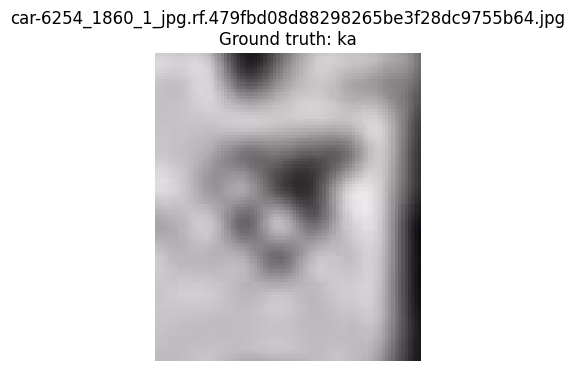


===== car-6362_701_1_jpg.rf.4728f96c197b3e976236692e62d7fc0a.jpg =====
{'class': 'ka', 'confidence': 0.6582, 'IoU': 0.857, 'box': [321.4, 39.5, 373.6, 93.3]}
{'class': 'ba', 'confidence': 0.2297, 'IoU': 0.869, 'box': [321.4, 40.7, 372.0, 93.5]}
{'class': 'kha', 'confidence': 0.1344, 'IoU': 0.868, 'box': [321.3, 39.7, 373.3, 93.6]}
{'class': 'ba', 'confidence': 0.0543, 'IoU': 0.854, 'box': [321.1, 39.5, 373.3, 93.1]}
{'class': 'gha', 'confidence': 0.0015, 'IoU': 0.841, 'box': [320.5, 39.9, 373.8, 92.9]}


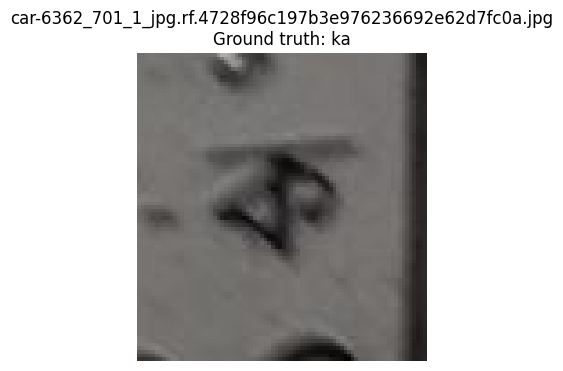

In [29]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)
MODEL_PATH = PROJECT / "models/character/character_best.pt"
DATA_ROOT = Path("/content/bd_plate_character_dataset")
IMAGE_DIR = DATA_ROOT / "images/validation"
LABEL_DIR = DATA_ROOT / "labels/validation"

TARGETS = [
    "car-6081_222_1_jpg.rf.388dbf97cae9da83a186ab0fb6d4a381",
    "car-6124_1_1_jpg.rf.d6761fb2193d00226cd4f3346dcbc307",
    "car-6254_1860_1_jpg.rf.479fbd08d88298265be3f28dc9755b64",
    "car-6362_701_1_jpg.rf.4728f96c197b3e976236692e62d7fc0a",
]

def box_iou(a, b):
    ix1 = max(a[0], b[0])
    iy1 = max(a[1], b[1])
    ix2 = min(a[2], b[2])
    iy2 = min(a[3], b[3])

    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0

model = YOLO(str(MODEL_PATH))
device = 0 if torch.cuda.is_available() else "cpu"

for target in TARGETS:
    image_path = next(
        (
            p for p in IMAGE_DIR.iterdir()
            if p.is_file() and p.stem == target
        ),
        None
    )

    if image_path is None:
        print("\nImage not found:", target)
        continue

    label_path = LABEL_DIR / f"{target}.txt"
    image = cv2.imread(str(image_path))

    if image is None or not label_path.exists():
        print("Image or label missing:", target)
        continue

    height, width = image.shape[:2]
    ground_truth = []

    for line in label_path.read_text(encoding="utf-8").splitlines():
        parts = line.split()

        if len(parts) != 5 or int(parts[0]) != 20:
            continue

        _, xc, yc, bw, bh = parts
        xc, yc, bw, bh = map(float, [xc, yc, bw, bh])

        ground_truth.append([
            (xc - bw / 2) * width,
            (yc - bh / 2) * height,
            (xc + bw / 2) * width,
            (yc + bh / 2) * height
        ])

    if not ground_truth:
        print("No KA ground-truth box:", target)
        continue

    result = model.predict(
        image,
        conf=0.001,
        iou=0.95,
        max_det=1000,
        imgsz=640,
        device=device,
        verbose=False
    )[0]

    print(f"\n===== {image_path.name} =====")

    boxes = result.boxes.xyxy.cpu().numpy()
    confidences = result.boxes.conf.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy()

    for gt in ground_truth:
        matches = []

        for box, confidence, class_id in zip(
            boxes, confidences, classes
        ):
            predicted_box = box.tolist()
            overlap = box_iou(gt, predicted_box)

            if overlap >= 0.30:
                matches.append({
                    "class": result.names[int(class_id)],
                    "confidence": round(float(confidence), 4),
                    "IoU": round(overlap, 3),
                    "box": [round(float(v), 1) for v in predicted_box]
                })

        for item in sorted(
            matches,
            key=lambda d: d["confidence"],
            reverse=True
        ):
            print(item)

        x1, y1, x2, y2 = map(int, gt)
        margin = 15

        cx1 = max(0, x1 - margin)
        cy1 = max(0, y1 - margin)
        cx2 = min(width, x2 + margin)
        cy2 = min(height, y2 + margin)

        crop = image[cy1:cy2, cx1:cx2]
        crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(4, 4))
        plt.imshow(crop)
        plt.title(f"{image_path.name}\nGround truth: ka")
        plt.axis("off")
        plt.show()


Image: car-6254_1860_1_jpg.rf.479fbd08d88298265be3f28dc9755b64.jpg
Ground-truth class: ka
Original crop dimensions: (88, 75)


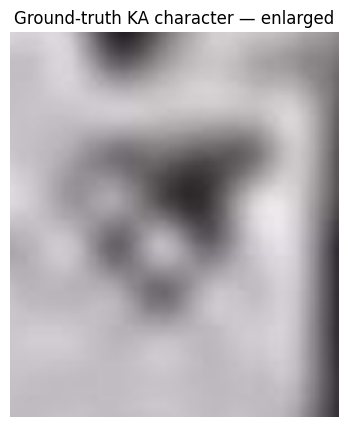

In [31]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

ROOT = Path("/content/bd_plate_character_dataset")
IMAGE_DIR = ROOT / "images" / "validation"
LABEL_DIR = ROOT / "labels" / "validation"

target = "car-6254_1860_1_jpg.rf.479fbd08d88298265be3f28dc9755b64"

image_path = next(IMAGE_DIR.glob(target + ".*"), None)
label_path = LABEL_DIR / f"{target}.txt"

if image_path is None or not label_path.exists():
    raise FileNotFoundError("Target image or label not found.")

image = cv2.imread(str(image_path))
height, width = image.shape[:2]

lines = label_path.read_text(encoding="utf-8").splitlines()
ka_boxes = []

for line in lines:
    parts = line.split()

    if len(parts) != 5 or int(parts[0]) != 20:
        continue

    _, xc, yc, bw, bh = parts
    xc, yc, bw, bh = map(float, [xc, yc, bw, bh])

    x1 = int((xc - bw / 2) * width)
    y1 = int((yc - bh / 2) * height)
    x2 = int((xc + bw / 2) * width)
    y2 = int((yc + bh / 2) * height)

    ka_boxes.append((x1, y1, x2, y2))

if not ka_boxes:
    raise ValueError("No KA annotation found.")

x1, y1, x2, y2 = ka_boxes[0]
margin = 12

x1 = max(0, x1 - margin)
y1 = max(0, y1 - margin)
x2 = min(width, x2 + margin)
y2 = min(height, y2 + margin)

crop = image[y1:y2, x1:x2]
crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

enlarged = cv2.resize(
    crop,
    None,
    fx=5,
    fy=5,
    interpolation=cv2.INTER_CUBIC
)

print("Image:", image_path.name)
print("Ground-truth class: ka")
print("Original crop dimensions:", crop.shape[:2])

plt.figure(figsize=(5, 5))
plt.imshow(enlarged)
plt.title("Ground-truth KA character — enlarged")
plt.axis("off")
plt.show()


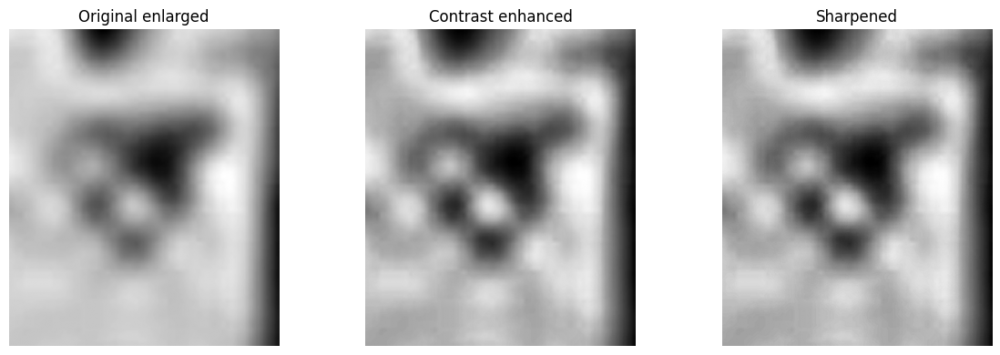

In [32]:

import cv2
import matplotlib.pyplot as plt
import numpy as np

if "crop" not in globals() or crop is None or crop.size == 0:
    raise ValueError("আগের cell থেকে character crop পাওয়া যায়নি।")

gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY) if crop.ndim == 3 and crop.shape[2] == 3 else crop.copy()

gray = np.asarray(gray, dtype=np.uint8)

upscaled = cv2.resize(
    gray, None, fx=5, fy=5,
    interpolation=cv2.INTER_CUBIC
)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(4, 4)
)

enhanced = clahe.apply(upscaled)

blurred = cv2.GaussianBlur(enhanced, (0, 0), 1.2)
sharpened = cv2.addWeighted(
    enhanced, 1.5, blurred, -0.5, 0
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(upscaled, cmap="gray")
axes[0].set_title("Original enlarged")

axes[1].imshow(enhanced, cmap="gray")
axes[1].set_title("Contrast enhanced")

axes[2].imshow(sharpened, cmap="gray")
axes[2].set_title("Sharpened")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


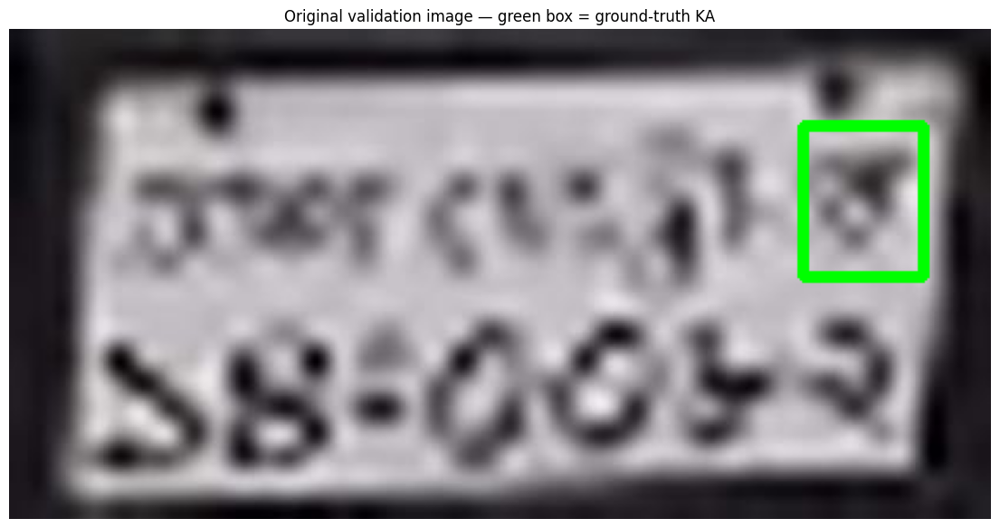

Original image dimensions: 416 x 208
Dataset label: ka


In [33]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

ROOT = Path("/content/bd_plate_character_dataset")
IMAGE_DIR = ROOT / "images" / "validation"
LABEL_DIR = ROOT / "labels" / "validation"

stem = "car-6254_1860_1_jpg.rf.479fbd08d88298265be3f28dc9755b64"

image_path = next(IMAGE_DIR.glob(stem + ".*"), None)
label_path = LABEL_DIR / f"{stem}.txt"

if image_path is None or not label_path.exists():
    raise FileNotFoundError("Original validation image or label not found.")

image = cv2.imread(str(image_path))
if image is None:
    raise ValueError("Could not read original image.")

height, width = image.shape[:2]

for line in label_path.read_text(encoding="utf-8").splitlines():
    parts = line.split()
    if len(parts) != 5 or int(parts[0]) != 20:
        continue

    _, xc, yc, bw, bh = parts
    xc, yc, bw, bh = map(float, [xc, yc, bw, bh])

    x1 = int((xc - bw / 2) * width)
    y1 = int((yc - bh / 2) * height)
    x2 = int((xc + bw / 2) * width)
    y2 = int((yc + bh / 2) * height)

    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.title("Original validation image — green box = ground-truth KA")
plt.axis("off")
plt.show()

print("Original image dimensions:", width, "x", height)
print("Dataset label: ka")


GHA training crops: 12


/tmp/ipykernel_530/1521715472.py:76: UserWarning: Glyph 2456 (\N{BENGALI LETTER GHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_530/1521715472.py:76: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2456 (\N{BENGALI LETTER GHA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Bengali natively.
  fig.canvas.print_figure(bytes_io, **kw)


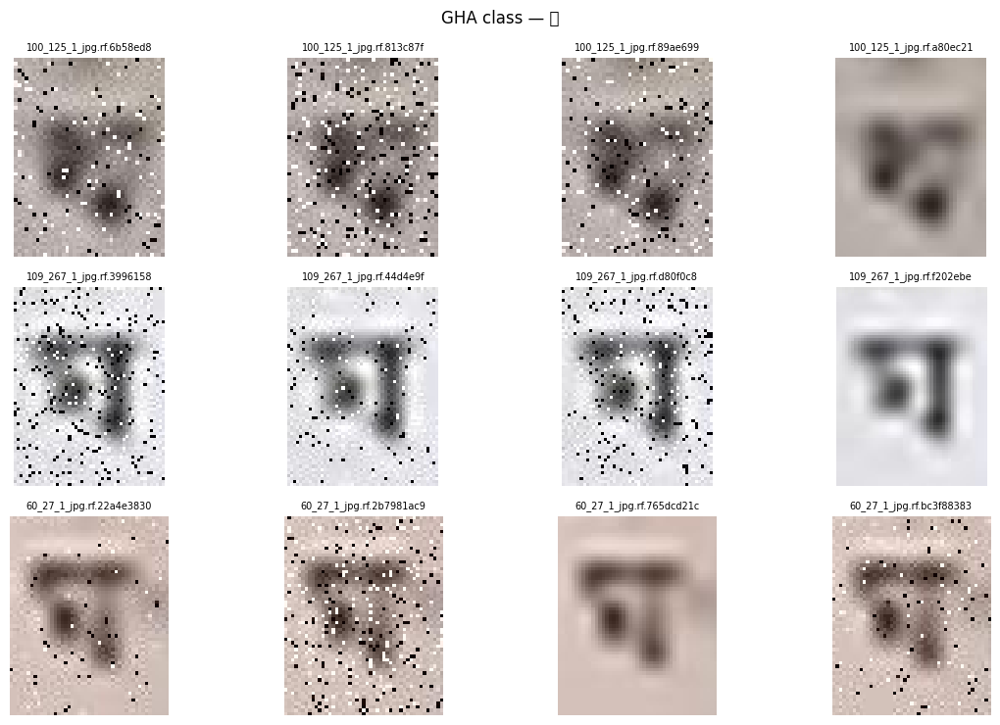

In [34]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import math

ROOT = Path("/content/bd_plate_character_dataset")
IMAGE_DIR = ROOT / "images" / "train"
LABEL_DIR = ROOT / "labels" / "train"

crops = []

for label_file in sorted(LABEL_DIR.glob("*.txt")):
    lines = label_file.read_text(encoding="utf-8").splitlines()
    targets = [
        line.split()
        for line in lines
        if line.strip() and line.split()[0] == "16"
    ]

    if not targets:
        continue

    image_path = next(
        (
            p for p in IMAGE_DIR.glob(label_file.stem + ".*")
            if p.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".jfif"
            }
        ),
        None
    )

    if image_path is None:
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        continue

    h, w = image.shape[:2]
    _, xc, yc, bw, bh = targets[0]
    xc, yc, bw, bh = map(float, [xc, yc, bw, bh])

    x1 = max(0, int((xc - bw / 2) * w))
    y1 = max(0, int((yc - bh / 2) * h))
    x2 = min(w, int((xc + bw / 2) * w))
    y2 = min(h, int((yc + bh / 2) * h))

    if x2 > x1 and y2 > y1:
        crop = cv2.cvtColor(
            image[y1:y2, x1:x2], cv2.COLOR_BGR2RGB
        )
        crops.append((label_file.name, crop))

    if len(crops) == 12:
        break

print("GHA training crops:", len(crops))

if crops:
    columns = 4
    rows = math.ceil(len(crops) / columns)
    fig, axes = plt.subplots(
        rows, columns, figsize=(12, rows * 2.5), squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (name, crop) in zip(axes.flat, crops):
        ax.imshow(crop)
        ax.set_title(name[:24], fontsize=7)
        ax.axis("off")

    plt.suptitle("GHA class — ঘ")
    plt.tight_layout()
    plt.show()


In [35]:

from pathlib import Path
import cv2
import numpy as np
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

IMAGE_PATH = Path("/content/unseen_vehicle_01.jpg")
LOCALIZER_PATH = PROJECT / "models/localization/localization_best.pt"
CHARACTER_PATH = PROJECT / "models/character/character_best.pt"

if not IMAGE_PATH.exists():
    raise FileNotFoundError(
        "Upload unseen_vehicle_01.jpg to Colab first."
    )

image = cv2.imread(str(IMAGE_PATH))
if image is None:
    raise ValueError("Could not read the image.")

device = 0 if torch.cuda.is_available() else "cpu"

localizer = YOLO(str(LOCALIZER_PATH))
character_model = YOLO(str(CHARACTER_PATH))

result = localizer.predict(
    image,
    conf=0.25,
    imgsz=640,
    device=device,
    verbose=False
)[0]

if result.boxes is None or len(result.boxes) == 0:
    raise RuntimeError("No plate detected.")

idx = int(result.boxes.conf.argmax())
x1, y1, x2, y2 = map(
    int, result.boxes.xyxy[idx].cpu().numpy()
)

h, w = image.shape[:2]
bw, bh = x2 - x1, y2 - y1

crop = image[
    max(0, y1 - int(bh * 0.15)):
    min(h, y2 + int(bh * 0.15)),
    max(0, x1 - int(bw * 0.05)):
    min(w, x2 + int(bw * 0.35))
]

print("Testing original character model at different resolutions.")

for imgsz in [640, 960, 1280]:
    prediction = character_model.predict(
        crop,
        conf=0.01,
        iou=0.7,
        imgsz=imgsz,
        device=device,
        verbose=False
    )[0]

    print(f"\n===== imgsz={imgsz} =====")

    if prediction.boxes is None:
        print("No detections")
        continue

    candidates = []

    for box, confidence, class_id in zip(
        prediction.boxes.xyxy.cpu().numpy(),
        prediction.boxes.conf.cpu().numpy(),
        prediction.boxes.cls.cpu().numpy()
    ):
        label = prediction.names[int(class_id)]
        cx = float((box[0] + box[2]) / 2)
        cy = float((box[1] + box[3]) / 2)

        if label in {"ka", "ha"} and cy < crop.shape[0] * 0.65:
            candidates.append((label, float(confidence), cx, cy))

    for label, confidence, cx, cy in sorted(
        candidates, key=lambda item: item[1], reverse=True
    ):
        print({
            "class": label,
            "confidence": round(confidence, 4),
            "x": round(cx, 1),
            "y": round(cy, 1)
        })

    if not candidates:
        print("No ka/ha candidate found.")


Testing original character model at different resolutions.

===== imgsz=640 =====
{'class': 'ha', 'confidence': 0.5235, 'x': 249.2, 'y': 71.1}
{'class': 'ka', 'confidence': 0.2092, 'x': 249.3, 'y': 71.0}

===== imgsz=960 =====
{'class': 'ka', 'confidence': 0.0651, 'x': 248.6, 'y': 71.6}

===== imgsz=1280 =====
{'class': 'ka', 'confidence': 0.0751, 'x': 248.5, 'y': 72.0}


In [36]:

from pathlib import Path
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

MODEL_PATH = PROJECT / "models/character/character_best.pt"

DATA_YAML = Path(
    "/content/bd_plate_character_ka_aug_20261018_144741/data.yaml"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not DATA_YAML.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_YAML}")

model = YOLO(str(MODEL_PATH))
device = 0 if torch.cuda.is_available() else "cpu"

for imgsz in [640, 960, 1280]:
    print(f"\n===== VALIDATION: imgsz={imgsz} =====")

    result = model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=imgsz,
        batch=8,
        device=device,
        workers=2,
        plots=False,
        verbose=False
    )

    print("Overall mAP50:", round(float(result.box.map50), 4))
    print("Overall mAP50-95:", round(float(result.box.map), 4))
    print("Precision:", round(float(result.box.mp), 4))
    print("Recall:", round(float(result.box.mr), 4))
    print("KA mAP50-95:", round(float(result.box.maps[20]), 4))
    print("HA mAP50-95:", round(float(result.box.maps[17]), 4))



===== VALIDATION: imgsz=640 =====
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,603,369 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 306.5±112.2 MB/s, size: 7.9 KB)
val: Scanning /content/bd_plate_character_ka_aug_20261018_144741/labels/validation.cache... 363 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 363/363 84.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 46/46 4.5it/s 10.2s
                   all        363       3180      0.908      0.922       0.94      0.708
Speed: 1.3ms preprocess, 16.3ms inference, 0.0ms loss, 3.3ms postprocess per image
Overall mAP50: 0.9401
Overall mAP50-95: 0.708
Precision: 0.9079
Recall: 0.9217
KA mAP50-95: 0.7375
HA mAP50-95: 0.5854

===== VALIDATION: imgsz=960 =====
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n

In [37]:

from pathlib import Path
import cv2
import numpy as np
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

IMAGE_PATH = Path("/content/unseen_vehicle_01.jpg")
LOCALIZER_PATH = PROJECT / "models/localization/localization_best.pt"
CHARACTER_PATH = PROJECT / "models/character/character_best.pt"

for path in [IMAGE_PATH, LOCALIZER_PATH, CHARACTER_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

image = cv2.imread(str(IMAGE_PATH))
if image is None:
    raise ValueError("Could not read the image.")

device = 0 if torch.cuda.is_available() else "cpu"

localizer = YOLO(str(LOCALIZER_PATH))
character_model = YOLO(str(CHARACTER_PATH))

result = localizer.predict(
    image, conf=0.25, imgsz=640,
    device=device, verbose=False
)[0]

if result.boxes is None or len(result.boxes) == 0:
    raise RuntimeError("No plate detected.")

idx = int(result.boxes.conf.argmax())
x1, y1, x2, y2 = map(
    int, result.boxes.xyxy[idx].cpu().numpy()
)

height, width = image.shape[:2]
bw, bh = x2 - x1, y2 - y1

variants = [
    ("Current crop", 0.05, 0.35, 0.15),
    ("Tighter right crop", 0.05, 0.10, 0.15),
    ("Medium right crop", 0.05, 0.20, 0.15),
    ("Wider crop", 0.05, 0.50, 0.15),
]

for name, left_pad, right_pad, vertical_pad in variants:
    cx1 = max(0, x1 - int(bw * left_pad))
    cx2 = min(width, x2 + int(bw * right_pad))
    cy1 = max(0, y1 - int(bh * vertical_pad))
    cy2 = min(height, y2 + int(bh * vertical_pad))

    crop = image[cy1:cy2, cx1:cx2]

    prediction = character_model.predict(
        crop,
        conf=0.01,
        iou=0.7,
        imgsz=640,
        device=device,
        verbose=False
    )[0]

    print(f"\n===== {name} =====")
    print("Crop dimensions:", crop.shape[1], "x", crop.shape[0])

    if prediction.boxes is None:
        print("No detections")
        continue

    candidates = []

    for box, confidence, class_id in zip(
        prediction.boxes.xyxy.cpu().numpy(),
        prediction.boxes.conf.cpu().numpy(),
        prediction.boxes.cls.cpu().numpy()
    ):
        label = prediction.names[int(class_id)]
        center_y = float((box[1] + box[3]) / 2)

        if label in {"ka", "ha"} and center_y < crop.shape[0] * 0.65:
            candidates.append((label, float(confidence)))

    if candidates:
        for label, confidence in sorted(
            candidates, key=lambda item: item[1], reverse=True
        ):
            print(f"{label}: {confidence:.4f}")
    else:
        print("No ka/ha candidate found.")



===== Current crop =====
Crop dimensions: 422 x 202
ha: 0.5235
ka: 0.2092

===== Tighter right crop =====
Crop dimensions: 347 x 202
ha: 0.1548
ka: 0.0210

===== Medium right crop =====
Crop dimensions: 377 x 202
ha: 0.3135
ka: 0.0216

===== Wider crop =====
Crop dimensions: 468 x 202
ka: 0.2146


In [39]:

from pathlib import Path
import cv2
import numpy as np
import torch
from google.colab import files
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

LOCALIZER_PATH = PROJECT / "models/localization/localization_best.pt"
CHARACTER_PATH = PROJECT / "models/character/character_best.pt"

for path in [LOCALIZER_PATH, CHARACTER_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing model: {path}")

uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No images uploaded.")

device = 0 if torch.cuda.is_available() else "cpu"

localizer = YOLO(str(LOCALIZER_PATH))
character_model = YOLO(str(CHARACTER_PATH))

for filename, contents in uploaded.items():
    image = cv2.imdecode(
        np.frombuffer(contents, dtype=np.uint8),
        cv2.IMREAD_COLOR
    )

    if image is None:
        print("Could not read:", filename)
        continue

    height, width = image.shape[:2]

    result = localizer.predict(
        image,
        conf=0.25,
        imgsz=640,
        device=device,
        verbose=False
    )[0]

    print(f"\n========== {filename} ==========")

    if result.boxes is None or len(result.boxes) == 0:
        print("No plate detected")
        continue

    idx = int(result.boxes.conf.argmax())
    x1, y1, x2, y2 = map(
        int, result.boxes.xyxy[idx].cpu().numpy()
    )

    bw, bh = x2 - x1, y2 - y1

    for right_padding in [0.35, 0.50]:
        cx1 = max(0, x1 - int(bw * 0.05))
        cx2 = min(width, x2 + int(bw * right_padding))
        cy1 = max(0, y1 - int(bh * 0.15))
        cy2 = min(height, y2 + int(bh * 0.15))

        crop = image[cy1:cy2, cx1:cx2]

        prediction = character_model.predict(
            crop,
            conf=0.01,
            iou=0.7,
            imgsz=640,
            device=device,
            verbose=False
        )[0]

        print(f"\nRight padding: {int(right_padding * 100)}%")

        if prediction.boxes is None:
            print("No characters detected")
            continue

        top = []

        for box, confidence, class_id in zip(
            prediction.boxes.xyxy.cpu().numpy(),
            prediction.boxes.conf.cpu().numpy(),
            prediction.boxes.cls.cpu().numpy()
        ):
            label = prediction.names[int(class_id)]
            center_y = float((box[1] + box[3]) / 2)

            if center_y < crop.shape[0] * 0.65:
                top.append((
                    float((box[0] + box[2]) / 2),
                    label,
                    float(confidence)
                ))

        for _, label, confidence in sorted(top):
            print(f"{label}: {confidence:.3f}")


Saving images (1).jfif to images (1).jfif
Saving images.jfif to images.jfif
Saving unseen_vehicle_01.jpg to unseen_vehicle_01 (2).jpg

========== images (1).jfif ==========

Right padding: 35%
1: 0.876
khulna: 0.010
khulna: 0.608
1: 0.843
1: 0.776
metro: 0.836
9: 0.143
2: 0.758
metro: 0.083
6: 0.218
5: 0.729
ta: 0.777
ba: 0.108

Right padding: 50%
1: 0.852
dhaka: 0.069
khulna: 0.790
1: 0.869
1: 0.841
metro: 0.812
2: 0.906
metro: 0.053
9: 0.014
6: 0.017
1: 0.046
5: 0.816
ta: 0.766
ba: 0.037

========== images.jfif ==========

Right padding: 35%
dhaka: 0.906
9: 0.886
metro: 0.900
9: 0.906
5: 0.893
ga: 0.872
7: 0.878

Right padding: 50%
dhaka: 0.894
9: 0.884
metro: 0.897
9: 0.876
5: 0.873
ga: 0.915
7: 0.859

========== unseen_vehicle_01 (2).jpg ==========

Right padding: 35%
1: 0.857
jashore: 0.032
chattogram: 0.996
1: 0.876
0: 0.024
0: 0.896
metro: 0.882
8: 0.888
3: 0.852
ha: 0.523
ka: 0.209
1: 0.877

Right padding: 50%
1: 0.866
chattogram: 0.947
dhaka: 0.334
1: 0.886
0: 0.847
metro: 0.8

In [40]:

from pathlib import Path
import cv2
import numpy as np
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

IMAGE_PATH = Path("/content/unseen_vehicle_01 (2).jpg")
if not IMAGE_PATH.exists():
    IMAGE_PATH = Path("/content/unseen_vehicle_01.jpg")

LOCALIZER = PROJECT / "models/localization/localization_best.pt"
CHARACTER = PROJECT / "models/character/character_best.pt"

image = cv2.imread(str(IMAGE_PATH))
if image is None:
    raise FileNotFoundError("Upload unseen_vehicle_01.jpg again.")

device = 0 if torch.cuda.is_available() else "cpu"
localizer = YOLO(str(LOCALIZER))
model = YOLO(str(CHARACTER))

result = localizer.predict(
    image, conf=0.25, imgsz=640,
    device=device, verbose=False
)[0]

idx = int(result.boxes.conf.argmax())
x1, y1, x2, y2 = map(
    int, result.boxes.xyxy[idx].cpu().numpy()
)

height, width = image.shape[:2]
bw, bh = x2 - x1, y2 - y1

cx1 = max(0, x1 - int(bw * 0.05))
cx2 = min(width, x2 + int(bw * 0.50))
cy1 = max(0, y1 - int(bh * 0.15))
cy2 = min(height, y2 + int(bh * 0.15))

crop = image[cy1:cy2, cx1:cx2]

plate_left = x1 - cx1
plate_right = x2 - cx1

prediction = model.predict(
    crop, conf=0.01, iou=0.7, imgsz=640,
    device=device, verbose=False
)[0]

print("Crop width:", crop.shape[1])
print("Original plate horizontal range:", plate_left, plate_right)
print("\nDetections:")

for box, confidence, class_id in zip(
    prediction.boxes.xyxy.cpu().numpy(),
    prediction.boxes.conf.cpu().numpy(),
    prediction.boxes.cls.cpu().numpy()
):
    bx1, by1, bx2, by2 = box
    label = prediction.names[int(class_id)]
    center_x = float((bx1 + bx2) / 2)
    center_y = float((by1 + by2) / 2)

    print({
        "class": label,
        "confidence": round(float(confidence), 4),
        "center_x": round(center_x, 1),
        "center_y": round(center_y, 1),
        "inside_original_plate_x_range": (
            plate_left <= center_x <= plate_right
        )
    })


Crop width: 468
Original plate horizontal range: 15 317

Detections:
{'class': 'chattogram', 'confidence': 0.9475, 'center_x': 86.1, 'center_y': 69.9, 'inside_original_plate_x_range': True}
{'class': '1', 'confidence': 0.8988, 'center_x': 266.4, 'center_y': 122.5, 'inside_original_plate_x_range': True}
{'class': '1', 'confidence': 0.8859, 'center_x': 94.3, 'center_y': 121.3, 'inside_original_plate_x_range': True}
{'class': 'metro', 'confidence': 0.8817, 'center_x': 170.0, 'center_y': 71.2, 'inside_original_plate_x_range': True}
{'class': '8', 'confidence': 0.8754, 'center_x': 191.8, 'center_y': 123.2, 'inside_original_plate_x_range': True}
{'class': '1', 'confidence': 0.866, 'center_x': 56.6, 'center_y': 121.2, 'inside_original_plate_x_range': True}
{'class': '3', 'confidence': 0.8498, 'center_x': 229.4, 'center_y': 122.2, 'inside_original_plate_x_range': True}
{'class': '0', 'confidence': 0.8474, 'center_x': 155.6, 'center_y': 122.1, 'inside_original_plate_x_range': True}
{'class': 'd

In [41]:

from pathlib import Path
import cv2
import numpy as np
import torch
from ultralytics import YOLO

PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

LOCALIZER_PATH = PROJECT / "models/localization/localization_best.pt"
CHARACTER_PATH = PROJECT / "models/character/character_best.pt"

image_paths = [
    Path("/content/images (1).jfif"),
    Path("/content/images.jfif"),
    Path("/content/unseen_vehicle_01 (2).jpg"),
]

for path in [LOCALIZER_PATH, CHARACTER_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing model: {path}")

device = 0 if torch.cuda.is_available() else "cpu"

localizer = YOLO(str(LOCALIZER_PATH))
character_model = YOLO(str(CHARACTER_PATH))

for image_path in image_paths:
    if not image_path.exists():
        print("Image not found:", image_path.name)
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        print("Could not read:", image_path.name)
        continue

    height, width = image.shape[:2]

    plate_result = localizer.predict(
        image,
        conf=0.25,
        imgsz=640,
        device=device,
        verbose=False
    )[0]

    print(f"\n===== {image_path.name} =====")

    if plate_result.boxes is None or len(plate_result.boxes) == 0:
        print("No plate detected")
        continue

    idx = int(plate_result.boxes.conf.argmax())
    x1, y1, x2, y2 = map(
        int, plate_result.boxes.xyxy[idx].cpu().numpy()
    )

    bw, bh = x2 - x1, y2 - y1

    cx1 = max(0, x1 - int(bw * 0.05))
    cx2 = min(width, x2 + int(bw * 0.50))
    cy1 = max(0, y1 - int(bh * 0.15))
    cy2 = min(height, y2 + int(bh * 0.15))

    crop = image[cy1:cy2, cx1:cx2]

    prediction = character_model.predict(
        crop,
        conf=0.01,
        iou=0.7,
        imgsz=640,
        agnostic_nms=True,
        device=device,
        verbose=False
    )[0]

    if prediction.boxes is None:
        print("No characters detected")
        continue

    detections = []

    for box, confidence, class_id in zip(
        prediction.boxes.xyxy.cpu().numpy(),
        prediction.boxes.conf.cpu().numpy(),
        prediction.boxes.cls.cpu().numpy()
    ):
        bx1, by1, bx2, by2 = box
        detections.append({
            "class": prediction.names[int(class_id)],
            "confidence": round(float(confidence), 4),
            "x": round(float((bx1 + bx2) / 2), 1),
            "y": round(float((by1 + by2) / 2), 1)
        })

    for item in sorted(detections, key=lambda d: (d["y"], d["x"])):
        print(item)



===== images (1).jfif =====
{'class': 'khulna', 'confidence': 0.7905, 'x': 36.8, 'y': 40.5}
{'class': 'metro', 'confidence': 0.8116, 'x': 72.6, 'y': 43.4}
{'class': 'metro', 'confidence': 0.0529, 'x': 81.9, 'y': 43.5}
{'class': 'ta', 'confidence': 0.7662, 'x': 100.8, 'y': 44.3}
{'class': '1', 'confidence': 0.8524, 'x': 25.8, 'y': 56.5}
{'class': '1', 'confidence': 0.8692, 'x': 38.1, 'y': 57.8}
{'class': '1', 'confidence': 0.8408, 'x': 59.9, 'y': 60.3}
{'class': '2', 'confidence': 0.9058, 'x': 73.9, 'y': 61.3}
{'class': '5', 'confidence': 0.8163, 'x': 87.4, 'y': 62.4}
{'class': '1', 'confidence': 0.8509, 'x': 101.2, 'y': 63.5}
{'class': '1', 'confidence': 0.0796, 'x': 184.8, 'y': 72.8}
{'class': '1', 'confidence': 0.0357, 'x': 185.4, 'y': 74.4}

===== images.jfif =====
{'class': 'ga', 'confidence': 0.9151, 'x': 139.3, 'y': 41.5}
{'class': 'metro', 'confidence': 0.8973, 'x': 96.6, 'y': 47.6}
{'class': 'dhaka', 'confidence': 0.8936, 'x': 42.3, 'y': 56.6}
{'class': '7', 'confidence': 0.85

In [42]:

from pathlib import Path
import shutil
import json
from datetime import datetime

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

BACKUP_DIR = DRIVE_PROJECT / "colab_artifacts" / "20261018"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

print("Saving Colab experiment artifacts to Google Drive...")

artifacts = [
    (
        Path("/content/bd_plate_character_ka_aug_20261018_144741"),
        BACKUP_DIR / "ka_augmented_dataset"
    ),
    (
        Path("/content/bd_platevision_ka_ha_audit"),
        BACKUP_DIR / "ka_ha_confusion_matrix"
    ),
    (
        Path("/content/diagnostic_plate_crop.jpg"),
        BACKUP_DIR / "diagnostic_plate_crop.jpg"
    ),
]

for source, destination in artifacts:
    if not source.exists():
        print("Not found, skipping:", source)
        continue

    if source.is_dir():
        shutil.copytree(
            source,
            destination,
            dirs_exist_ok=True
        )
    else:
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, destination)

    print("Saved:", destination)

experiment_paths = [
    DRIVE_PROJECT / "experiments" / "ka_balanced_t4_20261018_145008",
    DRIVE_PROJECT / "experiments" / "ka_controlled_20261018_154712",
]

summary = {
    "project": "Bangladesh License Plate Recognition",
    "saved_at": datetime.now().isoformat(),
    "original_model": str(
        DRIVE_PROJECT / "models" / "character" / "character_best.pt"
    ),
    "baseline_validation": {
        "map50": 0.9401,
        "map50_95": 0.708,
        "ka_map50_95": 0.7375,
        "ha_map50_95": 0.5854
    },
    "experiments": {}
}

for experiment in experiment_paths:
    best_model = experiment / "weights" / "best.pt"
    results_csv = experiment / "results.csv"

    summary["experiments"][experiment.name] = {
        "best_model_exists": best_model.exists(),
        "best_model": str(best_model),
        "results_csv_exists": results_csv.exists(),
        "results_csv": str(results_csv)
    }

    print(
        experiment.name,
        "| best.pt:", best_model.exists(),
        "| results.csv:", results_csv.exists()
    )

summary_path = BACKUP_DIR / "experiment_summary.json"
summary_path.write_text(
    json.dumps(summary, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nSummary saved:", summary_path)
print("\nBackup directory:", BACKUP_DIR)
print("Original production model was not modified.")


Saving Colab experiment artifacts to Google Drive...
Saved: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/colab_artifacts/20261018/ka_augmented_dataset
Saved: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/colab_artifacts/20261018/ka_ha_confusion_matrix
Saved: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/colab_artifacts/20261018/diagnostic_plate_crop.jpg
ka_balanced_t4_20261018_145008 | best.pt: True | results.csv: True
ka_controlled_20261018_154712 | best.pt: True | results.csv: True

Summary saved: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/colab_artifacts/20261018/experiment_summary.json

Backup directory: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/colab_artifacts/20261018
Original production model was not modified.
